# Clasificación de enfermedades en hojas de yuca mediante redes neuronales convolucionales

**Proyecto 2 de Visión Artificial**

**Integrantes:** Samuel Giraldo Roldán y Daniel Giraldo Roldán

**Conjunto de datos:** `cassava` de TensorFlow Datasets

**Fuente:** https://www.tensorflow.org/datasets/catalog/cassava

## 1. Introducción y objetivos

La yuca (*Manihot esculenta*) es un cultivo alimentario de amplio uso en regiones tropicales. Sus hojas pueden presentar daños visibles asociados con enfermedades y con plagas. Distinguir esas condiciones a partir de una fotografía de campo permite orientar una revisión agronómica, pero una red neuronal no sustituye el criterio de un especialista ni constituye un diagnóstico definitivo.

Este trabajo aborda esa tarea como un problema de **clasificación multiclase de imágenes**. Cada fotografía tiene una sola etiqueta principal. El conjunto `cassava` reúne 9.430 imágenes etiquetadas, con cinco clases y tres particiones oficiales: entrenamiento (5.656), validación (1.889) y prueba (1.885). Esas cifras se verifican al cargar el conjunto. Las clases cubren la hoja sana y cuatro condiciones fitosanitarias: tizón bacteriano (CBB), enfermedad de la raya marrón (CBSD), daño por ácaro verde (CGM) y enfermedad del mosaico (CMD). El código y el orden de las etiquetas se leen desde TensorFlow Datasets; no se añaden categorías.

La visión artificial tiene aquí una utilidad de apoyo: ordenar fotografías tomadas en campo, señalar casos que conviene revisar primero y estimar en qué clases el modelo se confunde. El resultado es una clasificación visual de las categorías del conjunto, no una confirmación de laboratorio ni una recomendación de tratamiento.

**Objetivo general.** Construir, comparar y evaluar modelos convolucionales con transferencia de aprendizaje y ajuste fino para clasificar las cinco categorías del conjunto `cassava`, seleccionando la configuración con mejor macro-F1 de validación.

**Objetivos específicos**

1. Describir el conjunto, su dominio, la variable objetivo y las particiones oficiales.
2. Explorar el balance de clases y mostrar imágenes reales de las cinco categorías.
3. Entrenar MobileNetV2 y ResNet50, inicializadas con ImageNet, en dos fases: cabeza nueva y ajuste fino parcial.
4. Comparar ocho configuraciones de arquitectura, tamaño de lote y dropout, sin usar el conjunto de prueba para elegir el modelo.
5. Evaluar una sola vez el modelo seleccionado sobre la partición oficial de prueba y analizar el desempeño por clase.

## 2. Configuración



In [1]:
import importlib.util
import subprocess
import sys

PAQUETES = {
    "tensorflow_datasets": "tensorflow-datasets",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "pandas": "pandas",
    "numpy": "numpy",
}

for modulo, paquete in PAQUETES.items():
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

In [2]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import gc
import json
import shutil
import time
import traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.utils.class_weight import compute_class_weight

import matplotlib
import sklearn

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

print("tensorflow", tf.__version__)
print("keras", tf.keras.__version__)
print("tensorflow_datasets", tfds.__version__)
print("numpy", np.__version__)
print("pandas", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib", matplotlib.__version__)
print("seaborn", sns.__version__)

tensorflow 2.21.0
keras 3.13.2
tensorflow_datasets 4.9.10
numpy 2.1.3
pandas 2.2.3
scikit-learn 1.6.1
matplotlib 3.10.0
seaborn 0.13.2


In [3]:
# Parámetros centrales. El modo completo es la ejecución del proyecto.
SEMILLA = 42
ALTURA = 224
ANCHURA = 224
LR_CABEZA = 1e-3
LR_FINETUNING = 1e-5
EPOCAS_CABEZA = 6
EPOCAS_FINETUNING = 8
PACIENCIA = 3
ARQUITECTURAS = ["MobileNetV2", "ResNet50"]
TAMANOS_LOTE = [16, 32]
DROPOUTS = [0.3, 0.5]
BUFFER_BARAJADO = 512
MODO_EXPERIMENTO = "completo"  # "completo" o "reducido"
USAR_PRECISION_MIXTA = True
USAR_GOOGLE_DRIVE = False

PREFIJO_FINETUNING = {
    "MobileNetV2": "block_14",
    "ResNet50": "conv5_block1",
}

ETIQUETAS_ESPERADAS = ["cbb", "cbsd", "cgm", "cmd", "healthy"]
DESCRIPCIONES = {
    "cbb": "Cassava Bacterial Blight (tizón bacteriano)",
    "cbsd": "Cassava Brown Streak Disease (raya marrón)",
    "cgm": "Cassava Green Mite (ácaro verde)",
    "cmd": "Cassava Mosaic Disease (mosaico)",
    "healthy": "Hoja sana",
}
CONTEOS_CATALOGO = {"train": 5656, "validation": 1889, "test": 1885}

import importlib.util

tf.keras.utils.set_random_seed(SEMILLA)
sns.set_theme(style="whitegrid", context="notebook")

EN_COLAB = importlib.util.find_spec("google.colab") is not None
gpus = tf.config.list_physical_devices("GPU")
print("Google Colab:", EN_COLAB)
print("GPUs:", gpus if gpus else "ninguna")

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as error:
        print("No se activó memory growth:", error)

if gpus and USAR_PRECISION_MIXTA:
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
    print("Política de precisión: mixed_float16")
else:
    tf.keras.mixed_precision.set_global_policy("float32")
    print("Política de precisión: float32")
    if not gpus:
        print("Para la malla completa en Colab: Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU.")

if USAR_GOOGLE_DRIVE:
    if not EN_COLAB:
        raise RuntimeError("USAR_GOOGLE_DRIVE solo puede usarse dentro de Google Colab.")
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTADOS = Path("/content/drive/MyDrive/vision_artificial_cassava/resultados")
else:
    RESULTADOS = Path("resultados")

DIR_FIGURAS = RESULTADOS / "figuras"
DIR_CHECKPOINTS = RESULTADOS / "checkpoints"
for carpeta in (RESULTADOS, DIR_FIGURAS, DIR_CHECKPOINTS):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Directorio de resultados:", RESULTADOS.resolve())
print("Entrada de las redes:", ALTURA, "x", ANCHURA)
print("Modo de experimentos:", MODO_EXPERIMENTO)

Google Colab: True
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Política de precisión: mixed_float16
Directorio de resultados: /content/resultados
Entrada de las redes: 224 x 224
Modo de experimentos: completo


In [5]:
def convertir(valor):
    if isinstance(valor, dict):
        return {str(clave): convertir(contenido) for clave, contenido in valor.items()}
    if isinstance(valor, (list, tuple)):
        return [convertir(contenido) for contenido in valor]
    if isinstance(valor, np.ndarray):
        return convertir(valor.tolist())
    if isinstance(valor, np.floating):
        return float(valor)
    if isinstance(valor, np.integer):
        return int(valor)
    if isinstance(valor, Path):
        return str(valor)
    return valor


def guardar_json(ruta, objeto):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_suffix(ruta.suffix + ".tmp")
    temporal.write_text(json.dumps(convertir(objeto), indent=2, ensure_ascii=False), encoding="utf-8")
    temporal.replace(ruta)


def cargar_json(ruta, valor_inicial):
    ruta = Path(ruta)
    if not ruta.exists():
        return valor_inicial
    return json.loads(ruta.read_text(encoding="utf-8"))


def guardar_figura(figura, nombre):
    ruta = DIR_FIGURAS / nombre
    figura.savefig(ruta, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(figura)
    print("Figura guardada:", ruta)


def liberar_memoria():
    tf.keras.backend.clear_session()
    gc.collect()
    if tf.config.list_physical_devices("GPU") and USAR_PRECISION_MIXTA:
        tf.keras.mixed_precision.set_global_policy("mixed_float16")
    else:
        tf.keras.mixed_precision.set_global_policy("float32")


RUTA_HISTORIALES = RESULTADOS / "historiales.json"
RUTA_RESUMEN = RESULTADOS / "resumen_experimentos.csv"
RUTA_MEJOR = RESULTADOS / "mejor_modelo.json"
RUTA_EVALUACION = RESULTADOS / "evaluacion_prueba.json"
RUTA_CONCLUSIONES = RESULTADOS / "conclusiones.txt"
RUTA_MODELO_FINAL = RESULTADOS / "mejor_modelo.keras"

## 3. Carga y descripción del dataset

El conjunto se descarga desde TensorFlow Datasets con `tfds.load("cassava", with_info=True)`. Pertenece al dominio agrícola: fotografías de hojas de yuca anotadas para el reto iCassava 2019. La variable objetivo es `label`, un entero de una clasificación multiclase con cinco categorías excluyentes. La imagen es RGB de tamaño espacial variable (`None, None, 3`) y tipo `uint8`. También se conserva el nombre de archivo.

Las particiones `train`, `validation` y `test` se mantienen separadas. El objeto de prueba se crea aquí para respetar la división oficial, pero no se usa para entrenar, para calcular pesos de clase ni para elegir el modelo.

In [7]:
%pip install -q importlib_resources

In [8]:
(ds_train, ds_validation, ds_test), info = tfds.load(
    "cassava",
    split=["train", "validation", "test"],
    with_info=True,
    as_supervised=False,
    shuffle_files=False,
)

print(info)
print()
print(info.description)
print()
print("Citación:")
print(info.citation)
print("Página del conjunto:", info.homepage)
print("Claves supervisadas:", info.supervised_keys)
print("Estructura de atributos:")
print(info.features)

nombres_clases = list(info.features["label"].names)
if nombres_clases != ETIQUETAS_ESPERADAS:
    raise RuntimeError(
        "Las etiquetas leídas del conjunto no coinciden con cassava de TensorFlow Datasets. "
        f"Obtenidas: {nombres_clases}."
    )
NUM_CLASES = len(nombres_clases)
particiones = {str(nombre): int(datos.num_examples) for nombre, datos in info.splits.items()}
faltantes = {"train", "validation", "test"} - set(particiones)
if faltantes:
    raise RuntimeError(f"Faltan particiones oficiales: {sorted(faltantes)}")

print("Etiquetas en el orden de TensorFlow Datasets:")
for indice, codigo in enumerate(nombres_clases):
    print(f"  {indice}: {codigo} — {DESCRIPCIONES[codigo]}")
print("Imágenes por partición:")
total = 0
for nombre in ("train", "validation", "test"):
    real = particiones[nombre]
    total += real
    print(f"  {nombre}: {real} (catálogo: {CONTEOS_CATALOGO[nombre]})")
    if real != CONTEOS_CATALOGO[nombre]:
        print("    El tamaño real difiere del catálogo. Se usará el tamaño de esta versión.")
print("Total de imágenes:", total)
print("Forma declarada de image:", info.features["image"].shape)
print("Tipo de image:", info.features["image"].dtype)
print("Tipo de label:", info.features["label"].dtype)
print("Número de clases:", info.features["label"].num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.


tfds.core.DatasetInfo(
    name='cassava',
    full_name='cassava/0.1.0',
    description="""
    Cassava consists of leaf images for the cassava plant depicting healthy and
    four (4) disease conditions; Cassava Mosaic Disease (CMD), Cassava Bacterial
    Blight (CBB), Cassava Greem Mite (CGM) and Cassava Brown Streak Disease (CBSD).
    Dataset consists of a total of 9430 labelled images.
    The 9430 labelled images are split into a training set (5656), a test set(1885)
    and a validation set (1889). The number of images per class are unbalanced with
    the two disease classes CMD and CBSD having 72% of the images.
    """,
    homepage='https://www.kaggle.com/c/cassava-disease/overview',
    data_dir='/root/tensorflow_datasets/cassava/0.1.0',
    file_format=tfrecord,
    download_size=1.26 GiB,
    dataset_size=1.26 GiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'image/filename': Text(shape=(), dtype=string),
        'labe

## 4. Análisis exploratorio

El perfil de cada partición recorre los ejemplos uno a uno y conserva conteos, dimensiones, canales y nombres de archivo. Solo se guardan cuatro imágenes por clase del conjunto de entrenamiento, para mostrarlas. Las imágenes de validación y de prueba no se almacenan en esta sección. Las de prueba se visualizan únicamente en la evaluación final.

In [9]:
def perfilar_particion(dataset, num_clases, ejemplos_por_clase=0, nombre="particion"):
    conteo = np.zeros(num_clases, dtype=np.int64)
    alturas = []
    anchos = []
    canales = []
    archivos = set()
    muestras = {indice: [] for indice in range(num_clases)}
    for indice, ejemplo in enumerate(dataset, start=1):
        etiqueta = int(ejemplo["label"].numpy())
        if etiqueta < 0 or etiqueta >= num_clases:
            raise RuntimeError(f"Etiqueta fuera de rango en {nombre}: {etiqueta}")
        conteo[etiqueta] += 1
        forma = ejemplo["image"].shape
        if len(forma) != 3:
            raise RuntimeError(f"Imagen sin tres dimensiones en {nombre}: {forma}")
        alturas.append(int(forma[0]))
        anchos.append(int(forma[1]))
        canales.append(int(forma[2]))
        archivos.add(ejemplo["image/filename"].numpy().decode("utf-8"))
        if ejemplos_por_clase and len(muestras[etiqueta]) < ejemplos_por_clase:
            muestras[etiqueta].append(ejemplo["image"].numpy())
        if indice % 1000 == 0:
            print(f"  {nombre}: {indice} ejemplos revisados")
    if ejemplos_por_clase == 0:
        muestras = {}
    return {
        "conteo": conteo,
        "alturas": np.asarray(alturas),
        "anchos": np.asarray(anchos),
        "canales": np.asarray(canales),
        "archivos": archivos,
        "muestras": muestras,
    }


print("Perfil de entrenamiento")
perfil_train = perfilar_particion(ds_train, NUM_CLASES, ejemplos_por_clase=4, nombre="train")
print("Perfil de validación")
perfil_validation = perfilar_particion(ds_validation, NUM_CLASES, nombre="validation")
print("Perfil de prueba")
perfil_test = perfilar_particion(ds_test, NUM_CLASES, nombre="test")
perfiles = {
    "train": perfil_train,
    "validation": perfil_validation,
    "test": perfil_test,
}

Perfil de entrenamiento
  train: 1000 ejemplos revisados
  train: 2000 ejemplos revisados
  train: 3000 ejemplos revisados
  train: 4000 ejemplos revisados
  train: 5000 ejemplos revisados
Perfil de validación
  validation: 1000 ejemplos revisados
Perfil de prueba
  test: 1000 ejemplos revisados


In [10]:
def verificar_particiones(perfiles_split, particiones_info):
    for nombre in ("train", "validation", "test"):
        observado = int(perfiles_split[nombre]["conteo"].sum())
        declarado = int(particiones_info[nombre])
        if observado != declarado:
            raise RuntimeError(f"{nombre}: el conteo recorrido ({observado}) no coincide con tfds ({declarado}).")
        canales = set(perfiles_split[nombre]["canales"].tolist())
        if canales != {3}:
            raise RuntimeError(f"{nombre}: se esperaban 3 canales RGB y se observó {canales}.")
    pares = (("train", "validation"), ("train", "test"), ("validation", "test"))
    for izquierda, derecha in pares:
        cruce = perfiles_split[izquierda]["archivos"] & perfiles_split[derecha]["archivos"]
        if cruce:
            raise RuntimeError(f"{len(cruce)} nombres de archivo aparecen en {izquierda} y en {derecha}.")
    print("Los tres recorridos coinciden con tfds y sus nombres de archivo no se cruzan.")


verificar_particiones(perfiles, particiones)

filas = []
for nombre in ("train", "validation", "test"):
    conteo = perfiles[nombre]["conteo"]
    total_split = int(conteo.sum())
    fila = {"particion": nombre, "imagenes": total_split}
    for indice, codigo in enumerate(nombres_clases):
        fila[f"{codigo}_n"] = int(conteo[indice])
        fila[f"{codigo}_pct"] = 100.0 * conteo[indice] / total_split
    mayor = int(np.argmax(conteo))
    menor = int(np.argmin(conteo))
    fila["clase_mayoritaria"] = nombres_clases[mayor]
    fila["clase_minoritaria"] = nombres_clases[menor]
    fila["razon_max_min"] = float(conteo[mayor] / conteo[menor])
    fila["pct_cmd_cbsd"] = float(fila["cmd_pct"] + fila["cbsd_pct"])
    filas.append(fila)

tabla_clases = pd.DataFrame(filas)
conteo_train = perfiles["train"]["conteo"].copy()
print("Conteos y porcentajes por partición")
display(tabla_clases)

print("La descripción oficial señala que CMD y CBSD concentran alrededor del 72 % de las imágenes.")
print("Porcentaje observado de cmd + cbsd:")
for _, fila in tabla_clases.iterrows():
    print(f"  {fila['particion']}: {fila['pct_cmd_cbsd']:.2f} %")
print(
    "En entrenamiento, la clase más frecuente es "
    f"{tabla_clases.loc[0, 'clase_mayoritaria']} y la menos frecuente es "
    f"{tabla_clases.loc[0, 'clase_minoritaria']} "
    f"(razón máximo/mínimo = {tabla_clases.loc[0, 'razon_max_min']:.2f})."
)

Los tres recorridos coinciden con tfds y sus nombres de archivo no se cruzan.
Conteos y porcentajes por partición


,particion,imagenes,cbb_n,cbb_pct,cbsd_n,cbsd_pct,cgm_n,cgm_pct,cmd_n,cmd_pct,healthy_n,healthy_pct,clase_mayoritaria,clase_minoritaria,razon_max_min,pct_cmd_cbsd
0,train,5656,466,8.239038,1443,25.512730,773,13.666902,2658,46.994342,316,5.586987,cmd,healthy,8.411392,72.507072
1,validation,1889,156,8.258338,482,25.516146,258,13.658020,887,46.956061,106,5.611435,cmd,healthy,8.367925,72.472208
2,test,1885,155,8.222812,481,25.517241,258,13.687003,886,47.002653,105,5.570292,cmd,healthy,8.438095,72.519894


La descripción oficial señala que CMD y CBSD concentran alrededor del 72 % de las imágenes.
Porcentaje observado de cmd + cbsd:
  train: 72.51 %
  validation: 72.47 %
  test: 72.52 %
En entrenamiento, la clase más frecuente es cmd y la menos frecuente es healthy (razón máximo/mínimo = 8.41).


In [11]:
def resumir_tamanos(perfil, nombre):
    pares = list(zip(perfil["alturas"].tolist(), perfil["anchos"].tolist()))
    frecuencias = pd.Series(pares).value_counts()
    resumen = {
        "particion": nombre,
        "altura_min": int(perfil["alturas"].min()),
        "altura_mediana": float(np.median(perfil["alturas"])),
        "altura_max": int(perfil["alturas"].max()),
        "ancho_min": int(perfil["anchos"].min()),
        "ancho_mediana": float(np.median(perfil["anchos"])),
        "ancho_max": int(perfil["anchos"].max()),
        "formas_distintas": int(frecuencias.shape[0]),
        "forma_mas_frecuente": str(frecuencias.index[0]),
        "n_forma_mas_frecuente": int(frecuencias.iloc[0]),
        "canales": sorted(set(perfil["canales"].tolist())),
    }
    return resumen

tabla_tamanos = pd.DataFrame([resumir_tamanos(perfiles[nombre], nombre) for nombre in ("train", "validation", "test")])
print("Dimensiones observadas. La ficha del conjunto declara tamaño espacial variable y tres canales.")
display(tabla_tamanos)

Dimensiones observadas. La ficha del conjunto declara tamaño espacial variable y tres canales.


,particion,altura_min,altura_mediana,altura_max,ancho_min,ancho_mediana,ancho_max,formas_distintas,forma_mas_frecuente,n_forma_mas_frecuente,canales
0,train,347,500.0,1240,420,534.0,1622,574,"(666, 500)",1442,[3]
1,validation,500,500.0,1078,434,546.0,1086,326,"(666, 500)",467,[3]
2,test,493,500.0,1027,456,567.0,1094,303,"(666, 500)",460,[3]


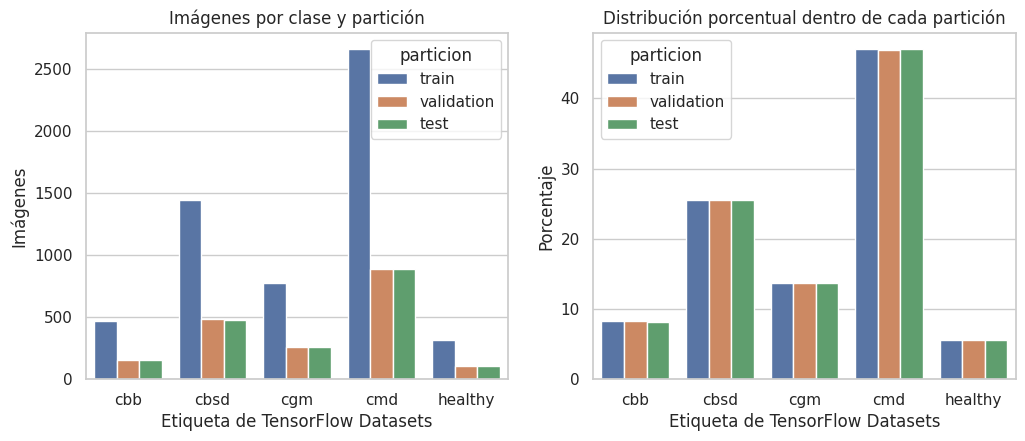

Figura guardada: resultados/figuras/distribucion_clases.png


In [12]:
conteos_largos = []
for nombre in ("train", "validation", "test"):
    for indice, codigo in enumerate(nombres_clases):
        conteos_largos.append({
            "particion": nombre,
            "clase": codigo,
            "imagenes": int(perfiles[nombre]["conteo"][indice]),
        })
datos_conteo = pd.DataFrame(conteos_largos)

figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=datos_conteo, x="clase", y="imagenes", hue="particion", ax=ejes[0])
ejes[0].set_title("Imágenes por clase y partición")
ejes[0].set_xlabel("Etiqueta de TensorFlow Datasets")
ejes[0].set_ylabel("Imágenes")

porcentajes = []
for nombre in ("train", "validation", "test"):
    total_split = perfiles[nombre]["conteo"].sum()
    for indice, codigo in enumerate(nombres_clases):
        porcentajes.append({
            "particion": nombre,
            "clase": codigo,
            "porcentaje": 100.0 * perfiles[nombre]["conteo"][indice] / total_split,
        })
sns.barplot(data=pd.DataFrame(porcentajes), x="clase", y="porcentaje", hue="particion", ax=ejes[1])
ejes[1].set_title("Distribución porcentual dentro de cada partición")
ejes[1].set_xlabel("Etiqueta de TensorFlow Datasets")
ejes[1].set_ylabel("Porcentaje")
guardar_figura(figura, "distribucion_clases.png")

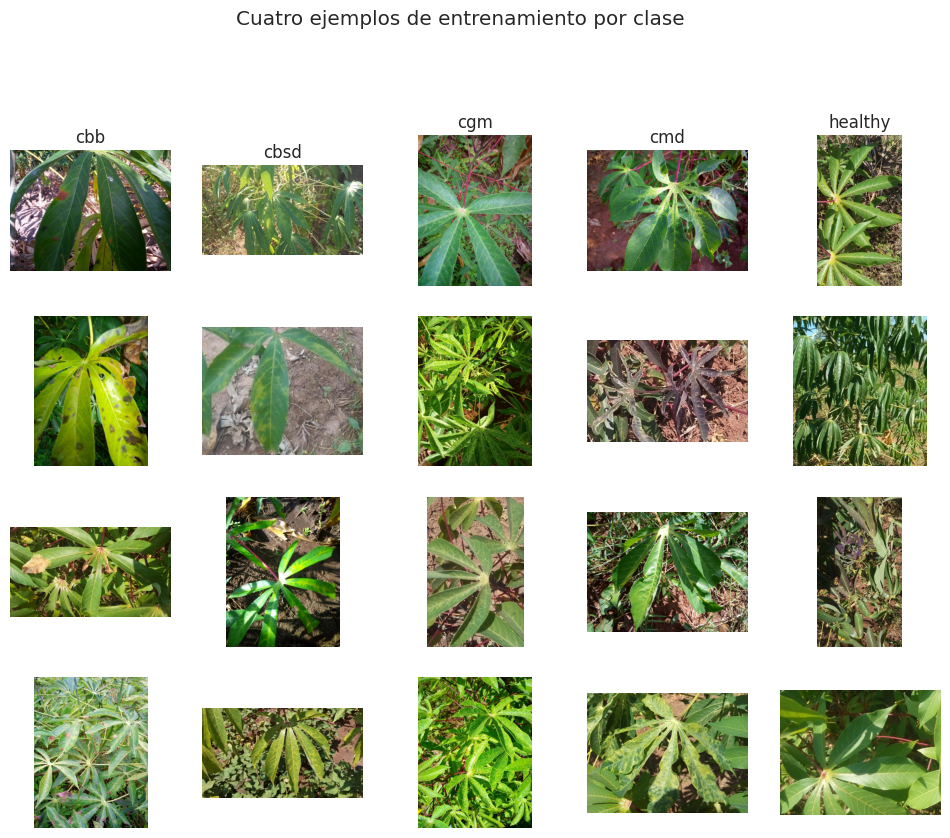

Figura guardada: resultados/figuras/ejemplos_entrenamiento.png
Las muestras visibles corresponden solo al split train.
healthy reúne hojas sin la condición anotada. Las otras cuatro etiquetas son condiciones fitosanitarias del conjunto.


In [13]:
filas_imagen = 4
figura, ejes = plt.subplots(filas_imagen, NUM_CLASES, figsize=(12, 9))
for columna, codigo in enumerate(nombres_clases):
    imagenes = perfiles["train"]["muestras"][columna]
    for fila in range(filas_imagen):
        eje = ejes[fila, columna]
        if fila < len(imagenes):
            eje.imshow(imagenes[fila])
        eje.axis("off")
        if fila == 0:
            eje.set_title(codigo)
figura.suptitle("Cuatro ejemplos de entrenamiento por clase", y=1.02)
guardar_figura(figura, "ejemplos_entrenamiento.png")
print("Las muestras visibles corresponden solo al split train.")
print("healthy reúne hojas sin la condición anotada. Las otras cuatro etiquetas son condiciones fitosanitarias del conjunto.")

## 5. Preparación de datos

Los tres splits originales permanecen separados. El entrenamiento se baraja y recibe aumentación moderada. Validación y prueba solo se redimensionan y se preprocesan. La entrada de ambas redes es de 224 × 224 píxeles.

No se aplica una división entre 255 además del preprocesamiento de la arquitectura. MobileNetV2 usa la escala de TensorFlow hacia el intervalo [-1, 1]. ResNet50 usa el modo Caffe: pasa de RGB a BGR y resta las medias de ImageNet. Cada pipeline llama solo a la función que corresponde a su red.

La aumentación de entrenamiento consiste en un volteo horizontal, un recorte aleatorio de hasta 10 % con regreso a 224 × 224, y cambios leves de brillo, contraste y saturación. Los valores se recortan al intervalo [0, 255] antes del preprocesamiento. Validación y prueba no se aumentan.

El desbalance se atiende de dos maneras. La selección del modelo usa macro-F1, que concede el mismo peso a cada clase, junto con las métricas por clase en la evaluación. Además, la pérdida de entrenamiento usa pesos de clase calculados únicamente con el conteo de `train`: peso de la clase c = N / (K · n_c). Esos pesos no entran en el cálculo de las métricas.

In [14]:
if np.any(conteo_train == 0):
    raise RuntimeError("Hay una clase sin ejemplos de entrenamiento; no se pueden calcular pesos.")

etiquetas_train = np.repeat(np.arange(NUM_CLASES), conteo_train)
pesos = compute_class_weight(class_weight="balanced", classes=np.arange(NUM_CLASES), y=etiquetas_train)
peso_clase = {int(indice): float(pesos[indice]) for indice in range(NUM_CLASES)}

tabla_pesos = pd.DataFrame({
    "clase": nombres_clases,
    "entrenamiento": conteo_train.astype(int),
    "peso": [peso_clase[indice] for indice in range(NUM_CLASES)],
})
print("Pesos de clase estimados solo con train")
display(tabla_pesos)
print("Suma de referencia N / (K * n_c). N =", int(conteo_train.sum()), "; K =", NUM_CLASES)

Pesos de clase estimados solo con train


,clase,entrenamiento,peso
0,cbb,466,2.427468
1,cbsd,1443,0.783922
2,cgm,773,1.463389
3,cmd,2658,0.425583
4,healthy,316,3.579747


Suma de referencia N / (K * n_c). N = 5656 ; K = 5


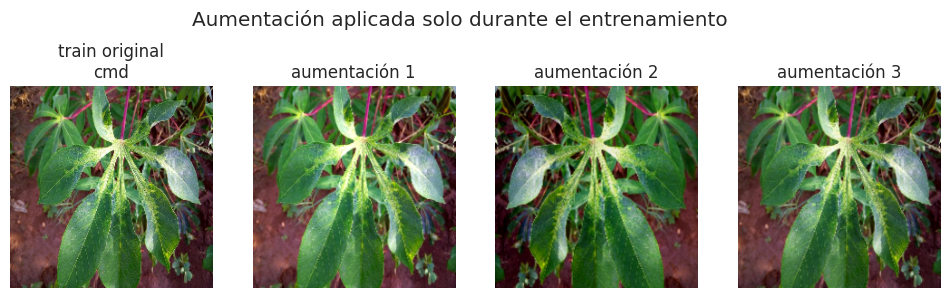

Figura guardada: resultados/figuras/ejemplo_aumentacion.png
Lote MobileNetV2: (8, 224, 224, 3) <dtype: 'float32'> min -1.0 max 1.0
Lote ResNet50: (8, 224, 224, 3) <dtype: 'float32'> min -123.68000030517578 max 151.06100463867188
Etiquetas del lote: [3, 2, 3, 3, 3, 4, 2, 3]
El conjunto de prueba todavía no entra a ningún pipeline de entrenamiento.


In [15]:
def obtener_preprocesador(arquitectura):
    if arquitectura == "MobileNetV2":
        return tf.keras.applications.mobilenet_v2.preprocess_input
    if arquitectura == "ResNet50":
        return tf.keras.applications.resnet50.preprocess_input
    raise ValueError(f"Arquitectura no configurada: {arquitectura}")


def aumentar_imagen(imagen):
    imagen = tf.image.random_flip_left_right(imagen)
    alto = tf.shape(imagen)[0]
    ancho = tf.shape(imagen)[1]
    canales = tf.shape(imagen)[2]
    escala = tf.random.uniform([], 0.9, 1.0)
    alto_crop = tf.maximum(tf.cast(tf.cast(alto, tf.float32) * escala, tf.int32), 1)
    ancho_crop = tf.maximum(tf.cast(tf.cast(ancho, tf.float32) * escala, tf.int32), 1)
    imagen = tf.image.random_crop(imagen, size=tf.stack([alto_crop, ancho_crop, canales]))
    imagen = tf.image.resize(imagen, tf.stack([alto, ancho]))
    imagen = tf.image.random_brightness(imagen, max_delta=20.0)
    imagen = tf.image.random_contrast(imagen, lower=0.9, upper=1.1)
    imagen = tf.image.random_saturation(imagen, lower=0.9, upper=1.1)
    return tf.clip_by_value(imagen, 0.0, 255.0)


def crear_pipeline(dataset, arquitectura, tamano_lote, entrenamiento, limite_lotes=None):
    preprocesar = obtener_preprocesador(arquitectura)

    def procesar(ejemplo):
        imagen = tf.image.resize(ejemplo["image"], [ALTURA, ANCHURA])
        imagen = tf.cast(imagen, tf.float32)
        if entrenamiento:
            imagen = aumentar_imagen(imagen)
        imagen = preprocesar(imagen)
        return imagen, tf.cast(ejemplo["label"], tf.int32)

    pipeline = dataset.map(procesar, num_parallel_calls=tf.data.AUTOTUNE)
    if entrenamiento:
        pipeline = pipeline.shuffle(BUFFER_BARAJADO, seed=SEMILLA, reshuffle_each_iteration=True)
    pipeline = pipeline.batch(tamano_lote, drop_remainder=False)
    if limite_lotes is not None:
        pipeline = pipeline.take(int(limite_lotes))
    opciones = tf.data.Options()
    if hasattr(opciones, "deterministic"):
        opciones.deterministic = not entrenamiento
    pipeline = pipeline.with_options(opciones)
    return pipeline.prefetch(tf.data.AUTOTUNE)


def crear_pipeline_visual(dataset, limite=1):
    def procesar(ejemplo):
        imagen = tf.image.resize(ejemplo["image"], [ALTURA, ANCHURA])
        imagen = tf.cast(tf.round(tf.clip_by_value(imagen, 0, 255)), tf.uint8)
        return imagen, tf.cast(ejemplo["label"], tf.int32)

    return dataset.map(procesar, num_parallel_calls=tf.data.AUTOTUNE).take(limite)


imagen_demo, etiqueta_demo = next(iter(crear_pipeline_visual(ds_train, limite=1)))
imagen_demo = tf.cast(imagen_demo, tf.float32)
figura, ejes = plt.subplots(1, 4, figsize=(12, 3.2))
ejes[0].imshow(tf.cast(tf.round(imagen_demo), tf.uint8).numpy())
ejes[0].set_title("train original\n" + nombres_clases[int(etiqueta_demo)])
ejes[0].axis("off")
for indice in range(1, 4):
    aumentada = tf.cast(tf.clip_by_value(aumentar_imagen(imagen_demo), 0, 255), tf.uint8).numpy()
    ejes[indice].imshow(aumentada)
    ejes[indice].set_title(f"aumentación {indice}")
    ejes[indice].axis("off")
figura.suptitle("Aumentación aplicada solo durante el entrenamiento", y=1.05)
guardar_figura(figura, "ejemplo_aumentacion.png")

lote_mobile, y_mobile = next(iter(crear_pipeline(ds_train, "MobileNetV2", 8, entrenamiento=False, limite_lotes=1)))
lote_resnet, y_resnet = next(iter(crear_pipeline(ds_train, "ResNet50", 8, entrenamiento=False, limite_lotes=1)))
print("Lote MobileNetV2:", lote_mobile.shape, lote_mobile.dtype, "min", float(tf.reduce_min(lote_mobile)), "max", float(tf.reduce_max(lote_mobile)))
print("Lote ResNet50:", lote_resnet.shape, lote_resnet.dtype, "min", float(tf.reduce_min(lote_resnet)), "max", float(tf.reduce_max(lote_resnet)))
if np.allclose(lote_mobile.numpy(), lote_resnet.numpy()):
    raise RuntimeError("Los preprocesamientos de MobileNetV2 y ResNet50 produjeron el mismo tensor.")
print("Etiquetas del lote:", y_mobile.numpy().tolist())
print("El conjunto de prueba todavía no entra a ningún pipeline de entrenamiento.")

## 6. Primera arquitectura: MobileNetV2

MobileNetV2 se carga con pesos de ImageNet y sin la cabeza original (`include_top=False`). Sobre los mapas de la base se coloca una agrupación global promedio, un dropout configurable y una capa densa con cinco unidades y activación softmax. La base se invoca con `training=False`, de modo que sus capas BatchNormalization permanecen en modo inferencia también durante el ajuste fino. Además, esas capas se dejan no entrenables para que no actualicen sus estadísticas.

El entrenamiento de cada configuración tiene dos fases y se recompila al cambiar las capas entrenables:

1. Toda la base queda congelada y solo se entrena la capa densa, con tasa de aprendizaje 1e-3.
2. Se descongelan las capas convolucionales desde `block_14` hasta el final de la base. BatchNormalization sigue congelada. La tasa de ajuste fino es 1e-5.

La parada temprana observa el macro-F1 de validación, con paciencia de 3 épocas, y restaura los pesos de la mejor época de esa fase. Esas dos fases se ejecutan dentro de la malla para cada hiperparámetro de MobileNetV2. Esta sección comprueba la arquitectura y que la descongelación sea real.

In [17]:
class ExactitudNoPonderada(tf.keras.metrics.Metric):
    def __init__(self, name="accuracy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.acertados = self.add_weight(name="acertados", initializer="zeros")
        self.total = self.add_weight(name="total", initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):
        reales = tf.reshape(tf.cast(y_true, tf.int32), [-1])
        predichas = tf.reshape(tf.cast(tf.argmax(y_pred, axis=-1), tf.int32), [-1])
        self.acertados.assign_add(tf.reduce_sum(tf.cast(tf.equal(reales, predichas), tf.float32)))
        self.total.assign_add(tf.cast(tf.size(reales), tf.float32))

    def result(self):
        return self.acertados / (self.total + tf.constant(1e-8, dtype=self.total.dtype))

    def reset_state(self):
        self.acertados.assign(0.0)
        self.total.assign(0.0)

    def reset_states(self):
        self.reset_state()


class MacroF1(tf.keras.metrics.Metric):
    def __init__(self, num_classes, name="macro_f1", **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = int(num_classes)
        self.matriz = self.add_weight(
            name="matriz",
            shape=(self.num_classes, self.num_classes),
            initializer="zeros",
        )

    def update_state(self, y_true, y_pred, sample_weight=None):
        reales = tf.reshape(tf.cast(y_true, tf.int32), [-1])
        predichas = tf.reshape(tf.cast(tf.argmax(y_pred, axis=-1), tf.int32), [-1])
        matriz = tf.math.confusion_matrix(reales, predichas, num_classes=self.num_classes, dtype=tf.float32)
        self.matriz.assign_add(matriz)

    def result(self):
        verdaderos = tf.linalg.diag_part(self.matriz)
        falsos_positivos = tf.reduce_sum(self.matriz, axis=0) - verdaderos
        falsos_negativos = tf.reduce_sum(self.matriz, axis=1) - verdaderos
        precision = verdaderos / (verdaderos + falsos_positivos + 1e-8)
        recall = verdaderos / (verdaderos + falsos_negativos + 1e-8)
        f1 = 2.0 * precision * recall / (precision + recall + 1e-8)
        return tf.reduce_mean(f1)

    def reset_state(self):
        self.matriz.assign(tf.zeros_like(self.matriz))

    def reset_states(self):
        self.reset_state()

    def get_config(self):
        configuracion = super().get_config()
        configuracion.update({"num_classes": self.num_classes})
        return configuracion


def es_batch_normalization(capa):
    return isinstance(capa, tf.keras.layers.BatchNormalization)


def construir_modelo(arquitectura, dropout, num_clases, pesos="imagenet"):
    if arquitectura == "MobileNetV2":
        base = tf.keras.applications.MobileNetV2(
            include_top=False,
            weights=pesos,
            input_shape=(ALTURA, ANCHURA, 3),
        )
    elif arquitectura == "ResNet50":
        base = tf.keras.applications.ResNet50(
            include_top=False,
            weights=pesos,
            input_shape=(ALTURA, ANCHURA, 3),
        )
    else:
        raise ValueError(f"Arquitectura no configurada: {arquitectura}")
    base.trainable = False
    entradas = tf.keras.Input(shape=(ALTURA, ANCHURA, 3), name="imagen")
    mapas = base(entradas, training=False)
    promedio = tf.keras.layers.GlobalAveragePooling2D(name="promedio_global")(mapas)
    regularizado = tf.keras.layers.Dropout(dropout, name="dropout")(promedio)
    salidas = tf.keras.layers.Dense(
        num_clases,
        activation="softmax",
        dtype="float32",
        name="probabilidades",
    )(regularizado)
    modelo = tf.keras.Model(entradas, salidas, name=arquitectura.lower() + "_yuca")
    if len(base.output_shape) != 4:
        raise RuntimeError(f"La base de {arquitectura} no entrega mapas convolucionales: {base.output_shape}")
    if modelo.output_shape[-1] != num_clases:
        raise RuntimeError("La cabeza no tiene una unidad por clase.")
    return modelo, base


def congelar_base(base):
    base.trainable = False


def descongelar_parcial(base, prefijo):
    base.trainable = True
    encontrado = False
    for capa in base.layers:
        if capa.name.startswith(prefijo):
            encontrado = True
        entrenable = encontrado and not es_batch_normalization(capa)
        capa.trainable = entrenable
    if not encontrado:
        nombres = [capa.name for capa in base.layers]
        raise RuntimeError(f"No existe una capa con prefijo {prefijo}. Capas: {nombres[:8]} ... {nombres[-8:]}")
    entrenables = [capa.name for capa in base.layers if capa.trainable]
    if not entrenables:
        raise RuntimeError("La descongelación parcial no dejó capas entrenables.")
    if len(entrenables) >= len(base.layers):
        raise RuntimeError("La descongelación no fue parcial: toda la base quedó entrenable.")
    return len(entrenables)


def texto_variable(variable):
    return " ".join(str(getattr(variable, atributo)) for atributo in ("path", "name") if hasattr(variable, atributo))


def verificar_fase_cabeza(modelo):
    nombres = [texto_variable(variable) for variable in modelo.trainable_weights]
    if len(nombres) < 2 or any("probabilidades" not in nombre for nombre in nombres):
        raise RuntimeError("La fase de cabeza debe entrenar solo la capa final. Pesos: " + str(nombres))
    return nombres


def verificar_fase_finetuning(modelo, base):
    bn_entrenables = [capa.name for capa in base.layers if es_batch_normalization(capa) and capa.trainable]
    if bn_entrenables:
        raise RuntimeError("BatchNormalization quedó entrenable: " + str(bn_entrenables[:5]))
    if not any(capa.trainable for capa in base.layers):
        raise RuntimeError("Ninguna capa de la base quedó descongelada.")
    nombres = [texto_variable(variable) for variable in modelo.trainable_weights]
    if not any("probabilidades" not in nombre for nombre in nombres):
        raise RuntimeError("El ajuste fino no incorporó pesos de la base.")
    return nombres


def describir_entrenabilidad(base, modelo, titulo):
    entrenables = [capa.name for capa in base.layers if capa.trainable]
    print(titulo)
    print("  capas de la base:", len(base.layers))
    print("  capas entrenables de la base:", len(entrenables))
    if entrenables:
        print("  primera entrenable:", entrenables[0])
        print("  última entrenable:", entrenables[-1])
    print("  BatchNormalization entrenables:", sum(es_batch_normalization(capa) and capa.trainable for capa in base.layers))
    print("  pesos entrenables:", [texto_variable(variable) for variable in modelo.trainable_weights])


def compilar_modelo(modelo, tasa):
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=tasa),
        loss="sparse_categorical_crossentropy",
        metrics=[ExactitudNoPonderada(name="accuracy"), MacroF1(NUM_CLASES, name="macro_f1")],
    )


def entrenar_fase(modelo, pipeline_train, pipeline_val, epocas, tasa, ruta_checkpoint, peso_clases):
    compilar_modelo(modelo, tasa)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_macro_f1",
            mode="max",
            patience=PACIENCIA,
            restore_best_weights=True,
            verbose=1,
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(ruta_checkpoint),
            monitor="val_macro_f1",
            mode="max",
            save_best_only=True,
            verbose=1,
        ),
    ]
    return modelo.fit(
        pipeline_train,
        validation_data=pipeline_val,
        epochs=epocas,
        class_weight=peso_clases,
        callbacks=callbacks,
        shuffle=False,
        verbose=1,
    )

In [18]:
modelo_mobile, base_mobile = construir_modelo("MobileNetV2", dropout=0.3, num_clases=NUM_CLASES)
print("Salida de la base MobileNetV2:", base_mobile.output_shape)
modelo_mobile.summary()
congelar_base(base_mobile)
verificar_fase_cabeza(modelo_mobile)
describir_entrenabilidad(base_mobile, modelo_mobile, "MobileNetV2 con la base congelada")
descongelar_parcial(base_mobile, PREFIJO_FINETUNING["MobileNetV2"])
verificar_fase_finetuning(modelo_mobile, base_mobile)
describir_entrenabilidad(base_mobile, modelo_mobile, "MobileNetV2 tras descongelar desde block_14")
del modelo_mobile, base_mobile
liberar_memoria()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Salida de la base MobileNetV2: (None, 7, 7, 1280)


Model: "mobilenetv2_yuca"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_global                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilidades (Dense)          │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

MobileNetV2 con la base congelada
  capas de la base: 154
  capas entrenables de la base: 0
  BatchNormalization entrenables: 0
  pesos entrenables: ['probabilidades/kernel kernel', 'probabilidades/bias bias']
MobileNetV2 tras descongelar desde block_14
  capas de la base: 154
  capas entrenables de la base: 19
  primera entrenable: block_14_expand
  última entrenable: out_relu
  BatchNormalization entrenables: 0
  pesos entrenables: ['block_14_expand/kernel kernel', 'block_14_depthwise/kernel kernel', 'block_14_project/kernel kernel', 'block_15_expand/kernel kernel', 'block_15_depthwise/kernel kernel', 'block_15_project/kernel kernel', 'block_16_expand/kernel kernel', 'block_16_depthwise/kernel kernel', 'block_16_project/kernel kernel', 'Conv_1/kernel kernel', 'probabilidades/kernel kernel', 'probabilidades/bias bias']


## 7. Segunda arquitectura: ResNet50

ResNet50 sigue el mismo esquema de transferencia: pesos de ImageNet, base sin la cabeza de 1.000 clases, agrupación global, dropout y softmax de cinco clases. El preprocesamiento es el propio de ResNet50 y no se comparte con MobileNetV2.

En el ajuste fino se descongelan las capas desde `conv5_block1`, el último bloque residual, y se mantienen en inferencia las capas BatchNormalization. Las particiones, la aumentación, los pesos de clase, la parada temprana y las tasas de aprendizaje son las mismas que en MobileNetV2. El tamaño de lote y el dropout cambian solo cuando así lo indica la malla, de la misma forma para las dos arquitecturas.

In [19]:
modelo_resnet, base_resnet = construir_modelo("ResNet50", dropout=0.3, num_clases=NUM_CLASES)
print("Salida de la base ResNet50:", base_resnet.output_shape)
modelo_resnet.summary()
congelar_base(base_resnet)
verificar_fase_cabeza(modelo_resnet)
describir_entrenabilidad(base_resnet, modelo_resnet, "ResNet50 con la base congelada")
descongelar_parcial(base_resnet, PREFIJO_FINETUNING["ResNet50"])
verificar_fase_finetuning(modelo_resnet, base_resnet)
describir_entrenabilidad(base_resnet, modelo_resnet, "ResNet50 tras descongelar desde conv5_block1")
del modelo_resnet, base_resnet
liberar_memoria()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Salida de la base ResNet50: (None, 7, 7, 2048)


Model: "resnet50_yuca"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_global                 │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilidades (Dense)          │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

ResNet50 con la base congelada
  capas de la base: 175
  capas entrenables de la base: 0
  BatchNormalization entrenables: 0
  pesos entrenables: ['probabilidades/kernel kernel', 'probabilidades/bias bias']
ResNet50 tras descongelar desde conv5_block1
  capas de la base: 175
  capas entrenables de la base: 22
  primera entrenable: conv5_block1_1_conv
  última entrenable: conv5_block3_out
  BatchNormalization entrenables: 0
  pesos entrenables: ['conv5_block1_1_conv/kernel kernel', 'conv5_block1_1_conv/bias bias', 'conv5_block1_2_conv/kernel kernel', 'conv5_block1_2_conv/bias bias', 'conv5_block1_0_conv/kernel kernel', 'conv5_block1_0_conv/bias bias', 'conv5_block1_3_conv/kernel kernel', 'conv5_block1_3_conv/bias bias', 'conv5_block2_1_conv/kernel kernel', 'conv5_block2_1_conv/bias bias', 'conv5_block2_2_conv/kernel kernel', 'conv5_block2_2_conv/bias bias', 'conv5_block2_3_conv/kernel kernel', 'conv5_block2_3_conv/bias bias', 'conv5_block3_1_conv/kernel kernel', 'conv5_block3_1_conv/bia

## 8. Malla de hiperparámetros

La malla completa cruza las dos arquitecturas con los tamaños de lote 16 y 32 y los dropout 0.3 y 0.5. Son ocho configuraciones. La tasa de la cabeza permanece en 1e-3 y la del ajuste fino en 1e-5. Cada una dispone de hasta 6 épocas para la cabeza y 8 para el ajuste fino, con parada temprana de 3 épocas. Esos límites se controlan en la celda de configuración.

El modo `reducido` entrena una sola configuración, MobileNetV2 con lote 16 y dropout 0.3, durante una época por fase y con pocos lotes. Sirve para comprobar que Colab ejecuta el flujo. Sus cifras no se escriben en `resumen_experimentos.csv` y no pueden usarse para elegir el modelo.

Un experimento solo queda como `completo` si terminan las dos fases y existe su checkpoint. Si una configuración falla, por ejemplo por memoria de la GPU, queda como incompleta y la malla continúa con la siguiente. Si la sesión se interrumpe y los archivos siguen disponibles, al volver a ejecutar esta celda se omiten los experimentos ya completados con la misma configuración. Un experimento incompleto se repite. Cada configuración conserva el checkpoint de la fase —cabeza o ajuste fino— que obtuvo mayor macro-F1 de validación; la accuracy de validación desempata. Si esas dos cifras coinciden, se conserva el ajuste fino.

Activar `USAR_GOOGLE_DRIVE` antes de llegar aquí guarda `resultados/` en Drive. En el disco local de Colab, un reinicio de la máquina virtual borra los archivos que no se hayan descargado.

In [22]:
def identificador_experimento(modo, arquitectura, tamano_lote, dropout, epocas_cabeza, epocas_finetuning):
    dropout_txt = f"{float(dropout):.1f}".replace(".", "p")
    return (
        f"{modo}_{arquitectura}_bs{int(tamano_lote)}_do{dropout_txt}"
        f"_c{int(epocas_cabeza)}_f{int(epocas_finetuning)}_p{int(PACIENCIA)}"
        f"_hlr{LR_CABEZA:.0e}_flr{LR_FINETUNING:.0e}"
    )


def definir_ejecucion(modo):
    configuraciones = [
        {"arquitectura": arquitectura, "batch_size": int(lote), "dropout": float(dropout)}
        for arquitectura in ARQUITECTURAS
        for lote in TAMANOS_LOTE
        for dropout in DROPOUTS
    ]
    if modo == "completo":
        if len(configuraciones) != 8:
            raise RuntimeError(f"La malla completa debe tener 8 configuraciones y tiene {len(configuraciones)}.")
        return configuraciones, EPOCAS_CABEZA, EPOCAS_FINETUNING, None, None
    if modo == "reducido":
        return [configuraciones[0]], 1, 1, 2, 1
    raise RuntimeError("MODO_EXPERIMENTO debe ser 'completo' o 'reducido'.")


def metricas_de_historia(historia):
    registro = historia.history
    necesario = ["loss", "accuracy", "macro_f1", "val_loss", "val_accuracy", "val_macro_f1"]
    ausentes = [clave for clave in necesario if clave not in registro or len(registro[clave]) == 0]
    if ausentes:
        raise RuntimeError(f"El historial no contiene las métricas esperadas: {ausentes}")
    indice = max(
        range(len(registro["val_macro_f1"])),
        key=lambda i: (registro["val_macro_f1"][i], registro["val_accuracy"][i]),
    )
    return {
        "epocas_ejecutadas": int(len(registro["val_macro_f1"])),
        "mejor_epoca": int(indice + 1),
        "val_macro_f1": float(registro["val_macro_f1"][indice]),
        "val_accuracy": float(registro["val_accuracy"][indice]),
        "val_loss": float(registro["val_loss"][indice]),
        "train_macro_f1": float(registro["macro_f1"][indice]),
        "train_accuracy": float(registro["accuracy"][indice]),
        "train_loss": float(registro["loss"][indice]),
        "history": {clave: [float(numero) for numero in valores] for clave, valores in registro.items()},
    }


def elegir_fase(cabeza, finetuning):
    clave_cabeza = (cabeza["val_macro_f1"], cabeza["val_accuracy"])
    clave_finetuning = (finetuning["val_macro_f1"], finetuning["val_accuracy"])
    if clave_finetuning > clave_cabeza:
        return "finetuning"
    if clave_cabeza > clave_finetuning:
        return "cabeza"
    return "finetuning"


def ids_malla_completa():
    configuraciones, epocas_cabeza, epocas_finetuning, _, _ = definir_ejecucion("completo")
    ids = []
    for configuracion in configuraciones:
        ids.append(identificador_experimento(
            "completo",
            configuracion["arquitectura"],
            configuracion["batch_size"],
            configuracion["dropout"],
            epocas_cabeza,
            epocas_finetuning,
        ))
    return configuraciones, ids


def fila_desde_registro(exp_id, configuracion, registro):
    base = {
        "experimento_id": exp_id,
        "estado": "pendiente",
        "arquitectura": configuracion["arquitectura"],
        "batch_size": configuracion["batch_size"],
        "dropout": configuracion["dropout"],
        "lr_cabeza": LR_CABEZA,
        "lr_finetuning": LR_FINETUNING,
        "epocas_cabeza": np.nan,
        "epocas_finetuning": np.nan,
        "mejor_epoca": np.nan,
        "fase_conservada": "",
        "val_accuracy": np.nan,
        "val_macro_f1": np.nan,
        "val_loss": np.nan,
        "val_macro_f1_cabeza": np.nan,
        "val_macro_f1_finetuning": np.nan,
        "tiempo_segundos": np.nan,
        "checkpoint": "",
        "error": "",
    }
    if not registro:
        return base
    base["estado"] = registro.get("estado", "incompleto")
    base["error"] = registro.get("error", "")
    for destino, origen in {
        "epocas_cabeza": "epocas_cabeza",
        "epocas_finetuning": "epocas_finetuning",
        "mejor_epoca": "mejor_epoca",
        "fase_conservada": "fase_conservada",
        "val_accuracy": "val_accuracy",
        "val_macro_f1": "val_macro_f1",
        "val_loss": "val_loss",
        "val_macro_f1_cabeza": "val_macro_f1_cabeza",
        "val_macro_f1_finetuning": "val_macro_f1_finetuning",
        "tiempo_segundos": "tiempo_segundos",
        "checkpoint": "checkpoint",
    }.items():
        if origen in registro and registro[origen] is not None:
            base[destino] = registro[origen]
    return base


def guardar_resumen(historiales):
    configuraciones, ids = ids_malla_completa()
    filas = [
        fila_desde_registro(exp_id, configuracion, historiales.get(exp_id))
        for exp_id, configuracion in zip(ids, configuraciones)
    ]
    temporal = RUTA_RESUMEN.with_suffix(".csv.tmp")
    pd.DataFrame(filas).to_csv(temporal, index=False)
    temporal.replace(RUTA_RESUMEN)


def experimento_reutilizable(registro, ruta_checkpoint, modo):
    return (
        isinstance(registro, dict)
        and registro.get("estado") == "completo"
        and registro.get("modo") == modo
        and registro.get("checkpoint")
        and Path(registro["checkpoint"]).exists()
        and Path(ruta_checkpoint).exists()
    )


configuraciones, epocas_cabeza_run, epocas_ft_run, limite_train, limite_val = definir_ejecucion(MODO_EXPERIMENTO)
historiales = cargar_json(RUTA_HISTORIALES, {})
print("Configuraciones de esta ejecución:", len(configuraciones))
print("Épocas máximas: cabeza =", epocas_cabeza_run, "; ajuste fino =", epocas_ft_run)
if MODO_EXPERIMENTO == "reducido":
    print("Modo reducido: los resultados no se usarán para la selección ni para las conclusiones del proyecto.")

for numero, configuracion in enumerate(configuraciones, start=1):
    exp_id = identificador_experimento(
        MODO_EXPERIMENTO,
        configuracion["arquitectura"],
        configuracion["batch_size"],
        configuracion["dropout"],
        epocas_cabeza_run,
        epocas_ft_run,
    )
    directorio = DIR_CHECKPOINTS / exp_id
    directorio.mkdir(parents=True, exist_ok=True)
    ruta_mejor = directorio / "mejor.keras"
    print(f"\nExperimento {numero}/{len(configuraciones)}: {exp_id}")
    if experimento_reutilizable(historiales.get(exp_id), ruta_mejor, MODO_EXPERIMENTO):
        print("  Ya está completo. Se conserva el checkpoint existente.")
        continue

    inicio = time.perf_counter()
    registro = {
        "experimento_id": exp_id,
        "modo": MODO_EXPERIMENTO,
        "estado": "incompleto",
        "arquitectura": configuracion["arquitectura"],
        "batch_size": configuracion["batch_size"],
        "dropout": configuracion["dropout"],
        "lr_cabeza": LR_CABEZA,
        "lr_finetuning": LR_FINETUNING,
        "epocas_max_cabeza": epocas_cabeza_run,
        "epocas_max_finetuning": epocas_ft_run,
        "paciencia": PACIENCIA,
        "semilla": SEMILLA,
        "checkpoint": str(ruta_mejor),
    }
    modelo = None
    try:
        pipeline_train = crear_pipeline(
            ds_train,
            configuracion["arquitectura"],
            configuracion["batch_size"],
            entrenamiento=True,
            limite_lotes=limite_train,
        )
        pipeline_val = crear_pipeline(
            ds_validation,
            configuracion["arquitectura"],
            configuracion["batch_size"],
            entrenamiento=False,
            limite_lotes=limite_val,
        )
        modelo, base = construir_modelo(
            configuracion["arquitectura"],
            configuracion["dropout"],
            NUM_CLASES,
        )
        congelar_base(base)
        pesos_cabeza = verificar_fase_cabeza(modelo)
        describir_entrenabilidad(base, modelo, "Fase 1, base congelada")
        ruta_cabeza = directorio / "fase_cabeza.keras"
        historia_cabeza = entrenar_fase(
            modelo, pipeline_train, pipeline_val, epocas_cabeza_run, LR_CABEZA, ruta_cabeza, peso_clase,
        )
        modelo.save(ruta_cabeza, include_optimizer=False)
        metricas_cabeza = metricas_de_historia(historia_cabeza)
        registro["capas_entrenables_base_cabeza"] = 0
        registro["pesos_cabeza"] = pesos_cabeza

        n_descongeladas = descongelar_parcial(base, PREFIJO_FINETUNING[configuracion["arquitectura"]])
        pesos_ft = verificar_fase_finetuning(modelo, base)
        describir_entrenabilidad(base, modelo, "Fase 2, ajuste fino parcial")
        ruta_ft = directorio / "fase_finetuning.keras"
        historia_ft = entrenar_fase(
            modelo, pipeline_train, pipeline_val, epocas_ft_run, LR_FINETUNING, ruta_ft, peso_clase,
        )
        modelo.save(ruta_ft, include_optimizer=False)
        metricas_ft = metricas_de_historia(historia_ft)
        fase = elegir_fase(metricas_cabeza, metricas_ft)
        origen = ruta_ft if fase == "finetuning" else ruta_cabeza
        shutil.copy2(origen, ruta_mejor)
        if not ruta_mejor.exists():
            raise RuntimeError("No se escribió el checkpoint del experimento.")
        for temporal_fase in (ruta_cabeza, ruta_ft):
            if temporal_fase.exists():
                temporal_fase.unlink()

        conservada = metricas_ft if fase == "finetuning" else metricas_cabeza
        registro.update({
            "estado": "completo",
            "epocas_cabeza": metricas_cabeza["epocas_ejecutadas"],
            "epocas_finetuning": metricas_ft["epocas_ejecutadas"],
            "mejor_epoca_cabeza": metricas_cabeza["mejor_epoca"],
            "mejor_epoca_finetuning": metricas_ft["mejor_epoca"],
            "mejor_epoca": conservada["mejor_epoca"],
            "fase_conservada": fase,
            "val_accuracy": conservada["val_accuracy"],
            "val_macro_f1": conservada["val_macro_f1"],
            "val_loss": conservada["val_loss"],
            "train_accuracy_mejor_epoca": conservada["train_accuracy"],
            "train_macro_f1_mejor_epoca": conservada["train_macro_f1"],
            "val_accuracy_cabeza": metricas_cabeza["val_accuracy"],
            "val_macro_f1_cabeza": metricas_cabeza["val_macro_f1"],
            "val_loss_cabeza": metricas_cabeza["val_loss"],
            "val_accuracy_finetuning": metricas_ft["val_accuracy"],
            "val_macro_f1_finetuning": metricas_ft["val_macro_f1"],
            "val_loss_finetuning": metricas_ft["val_loss"],
            "capas_entrenables_base_finetuning": int(n_descongeladas),
            "pesos_finetuning": pesos_ft,
            "historia_cabeza": metricas_cabeza["history"],
            "historia_finetuning": metricas_ft["history"],
        })
        print(
            "  Completo.",
            "fase conservada:", fase,
            "val_macro_f1:", round(registro["val_macro_f1"], 4),
            "val_accuracy:", round(registro["val_accuracy"], 4),
        )
    except Exception as error:
        registro["estado"] = "incompleto"
        registro["error"] = f"{type(error).__name__}: {error}"
        print("  Incompleto:", registro["error"])
        traceback.print_exc()
    finally:
        registro["tiempo_segundos"] = round(time.perf_counter() - inicio, 3)
        historiales[exp_id] = registro
        guardar_json(RUTA_HISTORIALES, historiales)
        if MODO_EXPERIMENTO == "completo":
            guardar_resumen(historiales)
        try:
            del modelo
            liberar_memoria()
        except Exception as error_memoria:
            print("No se pudo liberar la memoria de este experimento:", error_memoria)

if MODO_EXPERIMENTO == "completo":
    resumen_actual = pd.read_csv(RUTA_RESUMEN)
    print("\nResumen de la malla completa")
    display(resumen_actual)
    completos = int((resumen_actual["estado"] == "completo").sum())
    print(f"Experimentos completos: {completos}/8")
else:
    print("\nLa validación técnica terminó. Vuelva a MODO_EXPERIMENTO = 'completo' para la malla del proyecto.")

Configuraciones de esta ejecución: 8
Épocas máximas: cabeza = 6 ; ajuste fino = 8

Experimento 1/8: completo_MobileNetV2_bs16_do0p3_c6_f8_p3_hlr1e-03_flr1e-05
  Ya está completo. Se conserva el checkpoint existente.

Experimento 2/8: completo_MobileNetV2_bs16_do0p5_c6_f8_p3_hlr1e-03_flr1e-05
  Ya está completo. Se conserva el checkpoint existente.

Experimento 3/8: completo_MobileNetV2_bs32_do0p3_c6_f8_p3_hlr1e-03_flr1e-05
  Ya está completo. Se conserva el checkpoint existente.

Experimento 4/8: completo_MobileNetV2_bs32_do0p5_c6_f8_p3_hlr1e-03_flr1e-05
  Ya está completo. Se conserva el checkpoint existente.

Experimento 5/8: completo_ResNet50_bs16_do0p3_c6_f8_p3_hlr1e-03_flr1e-05
  Ya está completo. Se conserva el checkpoint existente.

Experimento 6/8: completo_ResNet50_bs16_do0p5_c6_f8_p3_hlr1e-03_flr1e-05
  Ya está completo. Se conserva el checkpoint existente.

Experimento 7/8: completo_ResNet50_bs32_do0p3_c6_f8_p3_hlr1e-03_flr1e-05
  Ya está completo. Se conserva el checkpoint 

,experimento_id,estado,arquitectura,batch_size,dropout,lr_cabeza,lr_finetuning,epocas_cabeza,epocas_finetuning,mejor_epoca,fase_conservada,val_accuracy,val_macro_f1,val_loss,val_macro_f1_cabeza,val_macro_f1_finetuning,tiempo_segundos,checkpoint,error
0,completo_MobileNetV2_bs16_do0p3_c6_f8_p3_hlr1e...,completo,MobileNetV2,16,0.3,0.001,0.00001,6,8,7,finetuning,0.757544,0.690329,0.691558,0.624084,0.690329,528.260,resultados/checkpoints/completo_MobileNetV2_bs...,NaN
1,completo_MobileNetV2_bs16_do0p5_c6_f8_p3_hlr1e...,completo,MobileNetV2,16,0.5,0.001,0.00001,6,8,8,finetuning,0.765484,0.700637,0.669340,0.621700,0.700637,503.568,resultados/checkpoints/completo_MobileNetV2_bs...,NaN
2,completo_MobileNetV2_bs32_do0p3_c6_f8_p3_hlr1e...,completo,MobileNetV2,32,0.3,0.001,0.00001,6,8,6,finetuning,0.754367,0.683884,0.686880,0.604706,0.683884,497.399,resultados/checkpoints/completo_MobileNetV2_bs...,NaN
3,completo_MobileNetV2_bs32_do0p5_c6_f8_p3_hlr1e...,completo,MobileNetV2,32,0.5,0.001,0.00001,6,7,4,finetuning,0.726840,0.661920,0.762606,0.632088,0.661920,417.696,resultados/checkpoints/completo_MobileNetV2_bs...,NaN
4,completo_ResNet50_bs16_do0p3_c6_f8_p3_hlr1e-03...,completo,ResNet50,16,0.3,0.001,0.00001,6,7,4,finetuning,0.812070,0.744056,0.634557,0.700185,0.744056,606.904,resultados/checkpoints/completo_ResNet50_bs16_...,NaN
5,completo_ResNet50_bs16_do0p5_c6_f8_p3_hlr1e-03...,completo,ResNet50,16,0.5,0.001,0.00001,6,8,5,finetuning,0.797247,0.738536,0.683906,0.658454,0.738536,676.651,resultados/checkpoints/completo_ResNet50_bs16_...,NaN
6,completo_ResNet50_bs32_do0p3_c6_f8_p3_hlr1e-03...,completo,ResNet50,32,0.3,0.001,0.00001,6,8,6,finetuning,0.805188,0.740565,0.718689,0.677604,0.740565,816.549,resultados/checkpoints/completo_ResNet50_bs32_...,NaN
7,completo_ResNet50_bs32_do0p5_c6_f8_p3_hlr1e-03...,completo,ResNet50,32,0.5,0.001,0.00001,5,8,8,finetuning,0.800953,0.731861,0.765317,0.649908,0.731861,757.842,resultados/checkpoints/completo_ResNet50_bs32_...,NaN


Experimentos completos: 8/8


## 9. Comparación y selección

La tabla siguiente reúne las ocho configuraciones. El modelo elegido es el de mayor macro-F1 de validación. Si hay empate, se usa la accuracy de validación. El conjunto de prueba no participa en esta decisión. Las comparaciones por arquitectura, dropout y tamaño de lote describen esta malla: cada celda se entrenó una vez, así que una diferencia pequeña no se interpreta como un efecto aislado del hiperparámetro.

Configuraciones de la malla


,experimento_id,estado,arquitectura,batch_size,dropout,lr_cabeza,lr_finetuning,epocas_cabeza,epocas_finetuning,mejor_epoca,fase_conservada,val_accuracy,val_macro_f1,val_loss,val_macro_f1_cabeza,val_macro_f1_finetuning,tiempo_segundos,checkpoint,error
4,completo_ResNet50_bs16_do0p3_c6_f8_p3_hlr1e-03...,completo,ResNet50,16,0.3,0.001,0.00001,6,7,4,finetuning,0.812070,0.744056,0.634557,0.700185,0.744056,606.904,resultados/checkpoints/completo_ResNet50_bs16_...,
6,completo_ResNet50_bs32_do0p3_c6_f8_p3_hlr1e-03...,completo,ResNet50,32,0.3,0.001,0.00001,6,8,6,finetuning,0.805188,0.740565,0.718689,0.677604,0.740565,816.549,resultados/checkpoints/completo_ResNet50_bs32_...,
5,completo_ResNet50_bs16_do0p5_c6_f8_p3_hlr1e-03...,completo,ResNet50,16,0.5,0.001,0.00001,6,8,5,finetuning,0.797247,0.738536,0.683906,0.658454,0.738536,676.651,resultados/checkpoints/completo_ResNet50_bs16_...,
7,completo_ResNet50_bs32_do0p5_c6_f8_p3_hlr1e-03...,completo,ResNet50,32,0.5,0.001,0.00001,5,8,8,finetuning,0.800953,0.731861,0.765317,0.649908,0.731861,757.842,resultados/checkpoints/completo_ResNet50_bs32_...,
1,completo_MobileNetV2_bs16_do0p5_c6_f8_p3_hlr1e...,completo,MobileNetV2,16,0.5,0.001,0.00001,6,8,8,finetuning,0.765484,0.700637,0.669340,0.621700,0.700637,503.568,resultados/checkpoints/completo_MobileNetV2_bs...,
0,completo_MobileNetV2_bs16_do0p3_c6_f8_p3_hlr1e...,completo,MobileNetV2,16,0.3,0.001,0.00001,6,8,7,finetuning,0.757544,0.690329,0.691558,0.624084,0.690329,528.260,resultados/checkpoints/completo_MobileNetV2_bs...,
2,completo_MobileNetV2_bs32_do0p3_c6_f8_p3_hlr1e...,completo,MobileNetV2,32,0.3,0.001,0.00001,6,8,6,finetuning,0.754367,0.683884,0.686880,0.604706,0.683884,497.399,resultados/checkpoints/completo_MobileNetV2_bs...,
3,completo_MobileNetV2_bs32_do0p5_c6_f8_p3_hlr1e...,completo,MobileNetV2,32,0.5,0.001,0.00001,6,7,4,finetuning,0.726840,0.661920,0.762606,0.632088,0.661920,417.696,resultados/checkpoints/completo_MobileNetV2_bs...,


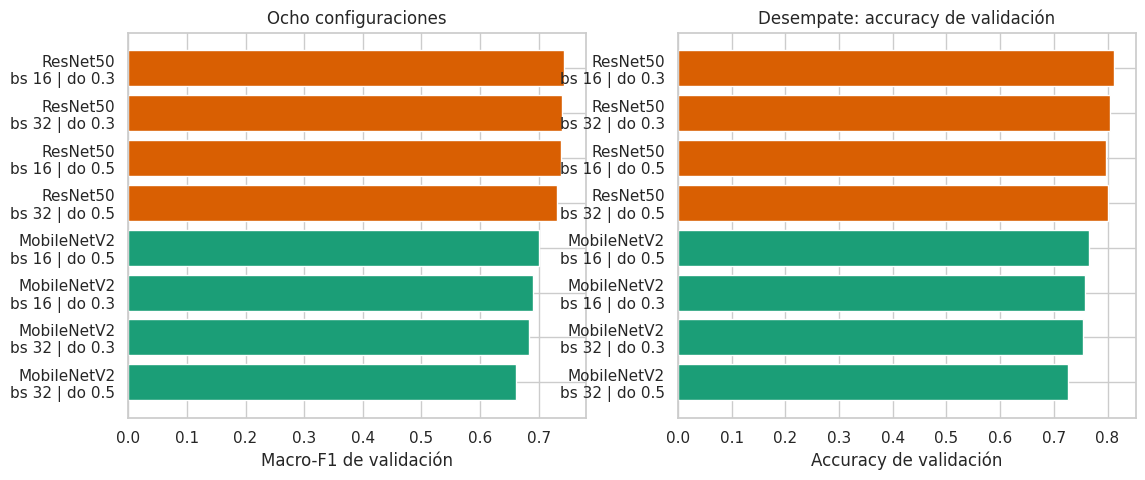

Figura guardada: resultados/figuras/comparacion_configuraciones.png


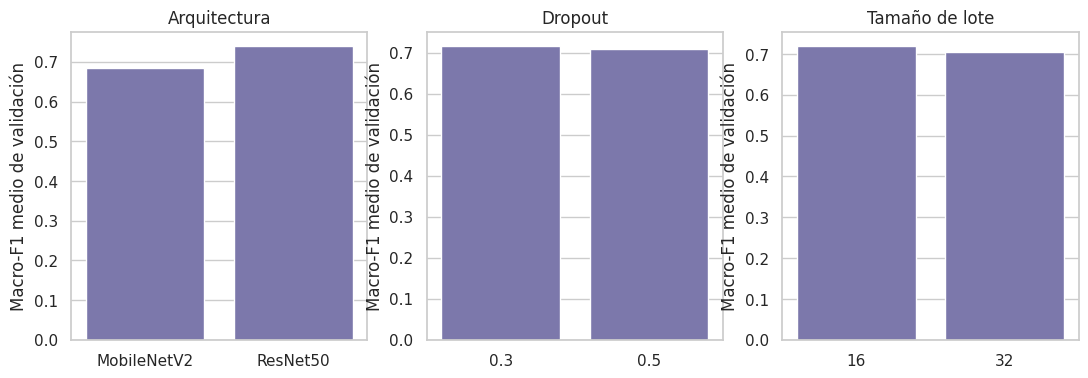

Figura guardada: resultados/figuras/efecto_hiperparametros.png


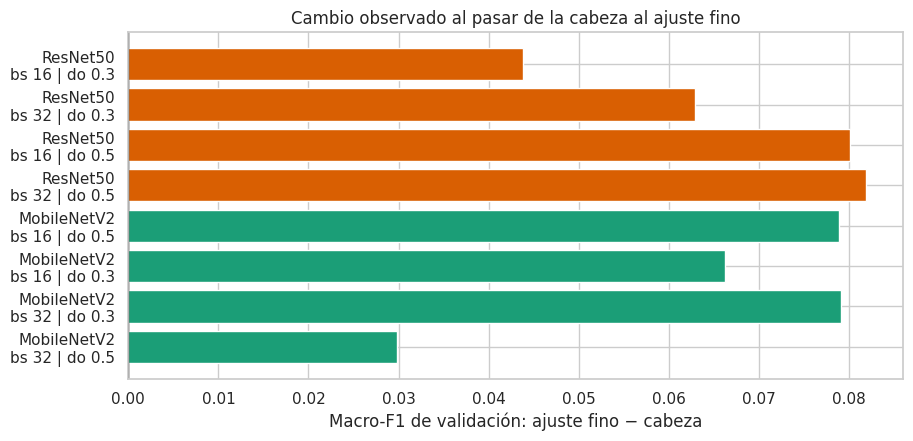

Figura guardada: resultados/figuras/cambio_finetuning.png


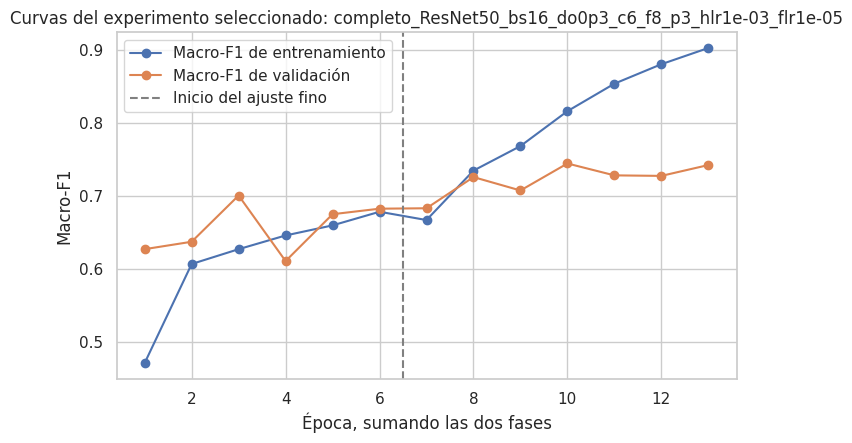

Figura guardada: resultados/figuras/curvas_modelo_seleccionado.png
Modelo seleccionado: completo_ResNet50_bs16_do0p3_c6_f8_p3_hlr1e-03_flr1e-05
Arquitectura: ResNet50
Lote: 16 | dropout: 0.3
Fase conservada: finetuning | mejor época de esa fase: 4
Macro-F1 de validación: 0.744055986404419
Accuracy de validación: 0.8120698928833008
Pérdida de validación: 0.6345572471618652
Macro-F1 medio de validación por arquitectura:
arquitectura
MobileNetV2    0.684193
ResNet50       0.738754
Mejor macro-F1 de validación dentro de cada arquitectura:
arquitectura
MobileNetV2    0.700637
ResNet50       0.744056
Macro-F1 medio de validación por dropout:
dropout
0.3    0.714708
0.5    0.708239
Macro-F1 medio de validación por tamaño de lote:
batch_size
16    0.718389
32    0.704558
En 8 de 8 configuraciones el ajuste fino superó el macro-F1 de validación de la cabeza.
Estas medias cruzan el resto de factores de la malla y proceden de una sola corrida por celda.
Ficha guardada: resultados/mejor_modelo.jso

In [23]:
if MODO_EXPERIMENTO != "completo":
    raise RuntimeError(
        "La selección está desactivada en modo reducido. "
        "Ese modo solo comprueba la ejecución y sus métricas no son el resultado del proyecto."
    )

historiales = cargar_json(RUTA_HISTORIALES, {})
configuraciones, ids = ids_malla_completa()
tabla = pd.DataFrame([
    fila_desde_registro(exp_id, configuracion, historiales.get(exp_id))
    for exp_id, configuracion in zip(ids, configuraciones)
])
guardar_resumen(historiales)
print("Configuraciones de la malla")
display(tabla.sort_values(["val_macro_f1", "val_accuracy"], ascending=False, na_position="last"))

incompletos = tabla.loc[tabla["estado"] != "completo", "experimento_id"].tolist()
if incompletos:
    raise RuntimeError(
        "No se selecciona un modelo porque hay experimentos que no terminaron: " + ", ".join(incompletos)
    )

tabla_ok = tabla.sort_values(["val_macro_f1", "val_accuracy"], ascending=False, na_position="last").reset_index(drop=True)
mejor_fila = tabla_ok.iloc[0]
registro_mejor = historiales[mejor_fila["experimento_id"]]

etiquetas_exp = [
    f"{fila.arquitectura}\nbs {int(fila.batch_size)} | do {fila.dropout:.1f}"
    for fila in tabla_ok.itertuples(index=False)
]
colores = ["#1b9e77" if arquitectura == "MobileNetV2" else "#d95f02" for arquitectura in tabla_ok["arquitectura"]]

figura, ejes = plt.subplots(1, 2, figsize=(13, 5))
ejes[0].barh(etiquetas_exp[::-1], tabla_ok["val_macro_f1"].to_numpy()[::-1], color=colores[::-1])
ejes[0].set_xlabel("Macro-F1 de validación")
ejes[0].set_title("Ocho configuraciones")
ejes[1].barh(etiquetas_exp[::-1], tabla_ok["val_accuracy"].to_numpy()[::-1], color=colores[::-1])
ejes[1].set_xlabel("Accuracy de validación")
ejes[1].set_title("Desempate: accuracy de validación")
guardar_figura(figura, "comparacion_configuraciones.png")

figura, ejes = plt.subplots(1, 3, figsize=(13, 4))
for eje, variable, titulo in zip(
    ejes,
    ["arquitectura", "dropout", "batch_size"],
    ["Arquitectura", "Dropout", "Tamaño de lote"],
):
    agrupado = tabla_ok.groupby(variable)["val_macro_f1"].mean().reset_index()
    sns.barplot(data=agrupado, x=variable, y="val_macro_f1", ax=eje, color="#7570b3")
    eje.set_title(titulo)
    eje.set_xlabel("")
    eje.set_ylabel("Macro-F1 medio de validación")
guardar_figura(figura, "efecto_hiperparametros.png")

deltas = tabla_ok["val_macro_f1_finetuning"] - tabla_ok["val_macro_f1_cabeza"]
figura, eje = plt.subplots(figsize=(10, 4.5))
eje.barh(etiquetas_exp[::-1], deltas.to_numpy()[::-1], color=colores[::-1])
eje.axvline(0.0, color="black", linewidth=1)
eje.set_xlabel("Macro-F1 de validación: ajuste fino − cabeza")
eje.set_title("Cambio observado al pasar de la cabeza al ajuste fino")
guardar_figura(figura, "cambio_finetuning.png")

historia_cabeza = registro_mejor["historia_cabeza"]
historia_ft = registro_mejor["historia_finetuning"]
epocas = list(range(1, len(historia_cabeza["val_macro_f1"]) + len(historia_ft["val_macro_f1"]) + 1))
curva_val = historia_cabeza["val_macro_f1"] + historia_ft["val_macro_f1"]
curva_train = historia_cabeza["macro_f1"] + historia_ft["macro_f1"]
corte = len(historia_cabeza["val_macro_f1"])
figura, eje = plt.subplots(figsize=(8, 4.5))
eje.plot(epocas, curva_train, marker="o", label="Macro-F1 de entrenamiento")
eje.plot(epocas, curva_val, marker="o", label="Macro-F1 de validación")
eje.axvline(corte + 0.5, color="gray", linestyle="--", label="Inicio del ajuste fino")
eje.set_xlabel("Época, sumando las dos fases")
eje.set_ylabel("Macro-F1")
eje.set_title("Curvas del experimento seleccionado: " + mejor_fila["experimento_id"])
eje.legend()
guardar_figura(figura, "curvas_modelo_seleccionado.png")

print("Modelo seleccionado:", mejor_fila["experimento_id"])
print("Arquitectura:", mejor_fila["arquitectura"])
print("Lote:", int(mejor_fila["batch_size"]), "| dropout:", float(mejor_fila["dropout"]))
print("Fase conservada:", mejor_fila["fase_conservada"], "| mejor época de esa fase:", int(mejor_fila["mejor_epoca"]))
print("Macro-F1 de validación:", float(mejor_fila["val_macro_f1"]))
print("Accuracy de validación:", float(mejor_fila["val_accuracy"]))
print("Pérdida de validación:", float(mejor_fila["val_loss"]))

media_arquitectura = tabla_ok.groupby("arquitectura")["val_macro_f1"].mean()
media_dropout = tabla_ok.groupby("dropout")["val_macro_f1"].mean()
media_lote = tabla_ok.groupby("batch_size")["val_macro_f1"].mean()
mejor_por_arquitectura = tabla_ok.groupby("arquitectura")["val_macro_f1"].max()
mejoras = int((tabla_ok["val_macro_f1_finetuning"] > tabla_ok["val_macro_f1_cabeza"]).sum())
print("Macro-F1 medio de validación por arquitectura:")
print(media_arquitectura.to_string())
print("Mejor macro-F1 de validación dentro de cada arquitectura:")
print(mejor_por_arquitectura.to_string())
print("Macro-F1 medio de validación por dropout:")
print(media_dropout.to_string())
print("Macro-F1 medio de validación por tamaño de lote:")
print(media_lote.to_string())
print(f"En {mejoras} de 8 configuraciones el ajuste fino superó el macro-F1 de validación de la cabeza.")
print("Estas medias cruzan el resto de factores de la malla y proceden de una sola corrida por celda.")

shutil.copy2(registro_mejor["checkpoint"], RUTA_MODELO_FINAL)
ficha_mejor = {
    "experimento_id": registro_mejor["experimento_id"],
    "modo": "completo",
    "arquitectura": registro_mejor["arquitectura"],
    "batch_size": registro_mejor["batch_size"],
    "dropout": registro_mejor["dropout"],
    "lr_cabeza": registro_mejor["lr_cabeza"],
    "lr_finetuning": registro_mejor["lr_finetuning"],
    "fase_conservada": registro_mejor["fase_conservada"],
    "mejor_epoca": registro_mejor["mejor_epoca"],
    "val_accuracy": registro_mejor["val_accuracy"],
    "val_macro_f1": registro_mejor["val_macro_f1"],
    "val_loss": registro_mejor["val_loss"],
    "val_macro_f1_cabeza": registro_mejor["val_macro_f1_cabeza"],
    "val_macro_f1_finetuning": registro_mejor["val_macro_f1_finetuning"],
    "checkpoint": str(RUTA_MODELO_FINAL),
    "criterio": "Mayor macro-F1 de validación. Accuracy de validación como desempate. El conjunto de prueba no participó.",
}
guardar_json(RUTA_MEJOR, ficha_mejor)
print("Ficha guardada:", RUTA_MEJOR)
print("Modelo guardado:", RUTA_MODELO_FINAL)

## 10. Evaluación final

Se carga el checkpoint elegido en la sección anterior y se evalúa sobre el split oficial `test`. Esta partición no se usó para entrenar ni para escoger arquitectura o hiperparámetros. Las métricas de esta sección salen de las predicciones de esta ejecución.

Accuracy de prueba: 0.826
Precisión macro: 0.7551
Recall macro: 0.7653
F1 macro: 0.7553

              precision    recall  f1-score   support

         cbb       0.61      0.54      0.57       155
        cbsd       0.82      0.77      0.79       481
         cgm       0.82      0.72      0.76       258
         cmd       0.89      0.94      0.91       886
     healthy       0.64      0.87      0.73       105

    accuracy                           0.83      1885
   macro avg       0.76      0.77      0.76      1885
weighted avg       0.83      0.83      0.82      1885



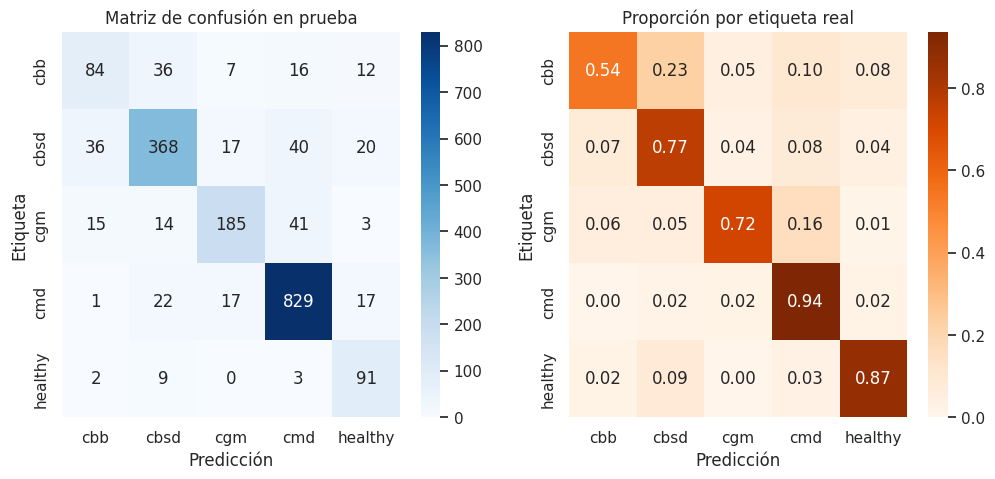

Figura guardada: resultados/figuras/matriz_confusion_prueba.png


In [24]:
ficha_mejor = cargar_json(RUTA_MEJOR, None)
if not isinstance(ficha_mejor, dict) or ficha_mejor.get("modo") != "completo":
    raise RuntimeError("No hay un modelo seleccionado con la malla completa.")
if not RUTA_MODELO_FINAL.exists():
    raise RuntimeError("No se encontró resultados/mejor_modelo.keras.")

modelo_final = tf.keras.models.load_model(
    RUTA_MODELO_FINAL,
    compile=False,
    custom_objects={"ExactitudNoPonderada": ExactitudNoPonderada, "MacroF1": MacroF1},
)
if modelo_final.output_shape[-1] != NUM_CLASES:
    raise RuntimeError("El modelo cargado no tiene cinco salidas.")

pipeline_prueba = crear_pipeline(
    ds_test,
    ficha_mejor["arquitectura"],
    int(ficha_mejor["batch_size"]),
    entrenamiento=False,
    limite_lotes=None,
)

y_true = []
y_prob = []
for lote_x, lote_y in pipeline_prueba:
    y_prob.append(modelo_final.predict(lote_x, verbose=0))
    y_true.append(lote_y.numpy())
y_prob = np.concatenate(y_prob, axis=0)
y_true = np.concatenate(y_true, axis=0).astype(int)
y_pred = np.argmax(y_prob, axis=1).astype(int)

cardinalidad_test = int(particiones["test"])
if len(y_true) != cardinalidad_test:
    raise RuntimeError(f"La evaluación cubrió {len(y_true)} imágenes y el split test tiene {cardinalidad_test}.")

metricas_prueba = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
    "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
    "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    "f1_por_clase": {
        codigo: float(valor)
        for codigo, valor in zip(nombres_clases, f1_score(y_true, y_pred, average=None, labels=list(range(NUM_CLASES)), zero_division=0))
    },
}
reporte = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASES)),
    target_names=nombres_clases,
    output_dict=True,
    zero_division=0,
)
matriz = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASES)))
print("Accuracy de prueba:", round(metricas_prueba["accuracy"], 4))
print("Precisión macro:", round(metricas_prueba["precision_macro"], 4))
print("Recall macro:", round(metricas_prueba["recall_macro"], 4))
print("F1 macro:", round(metricas_prueba["f1_macro"], 4))
print()
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASES)),
    target_names=nombres_clases,
    zero_division=0,
))

figura, ejes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=nombres_clases, yticklabels=nombres_clases, ax=ejes[0])
ejes[0].set_xlabel("Predicción")
ejes[0].set_ylabel("Etiqueta")
ejes[0].set_title("Matriz de confusión en prueba")
matriz_fila = matriz / np.maximum(matriz.sum(axis=1, keepdims=True), 1)
sns.heatmap(matriz_fila, annot=True, fmt=".2f", cmap="Oranges", xticklabels=nombres_clases, yticklabels=nombres_clases, ax=ejes[1])
ejes[1].set_xlabel("Predicción")
ejes[1].set_ylabel("Etiqueta")
ejes[1].set_title("Proporción por etiqueta real")
guardar_figura(figura, "matriz_confusion_prueba.png")

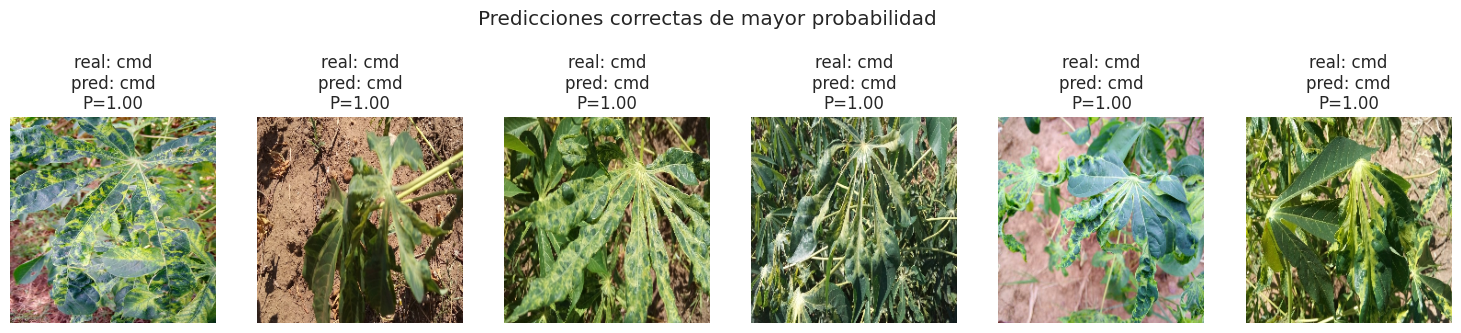

Figura guardada: resultados/figuras/predicciones_correctas.png


,indice,real,predicha,probabilidad_predicha,p_cbb,p_cbsd,p_cgm,p_cmd,p_healthy
0,1622,cmd,cmd,1.000000,3.152966e-11,5.189631e-07,3.422444e-09,1.000000,1.064745e-17
1,100,cmd,cmd,0.999999,3.513007e-09,4.873933e-07,1.237320e-07,0.999999,1.622892e-13
2,1868,cmd,cmd,0.999999,4.622405e-08,3.839410e-08,7.121361e-07,0.999999,2.357418e-13
3,600,cmd,cmd,0.999999,5.531121e-09,5.308235e-07,9.222377e-08,0.999999,2.506522e-07
4,344,cmd,cmd,0.999999,3.774235e-07,3.804704e-07,3.598495e-07,0.999999,1.161437e-13
5,374,cmd,cmd,0.999999,2.133811e-07,7.891552e-07,4.831338e-07,0.999999,1.446885e-09


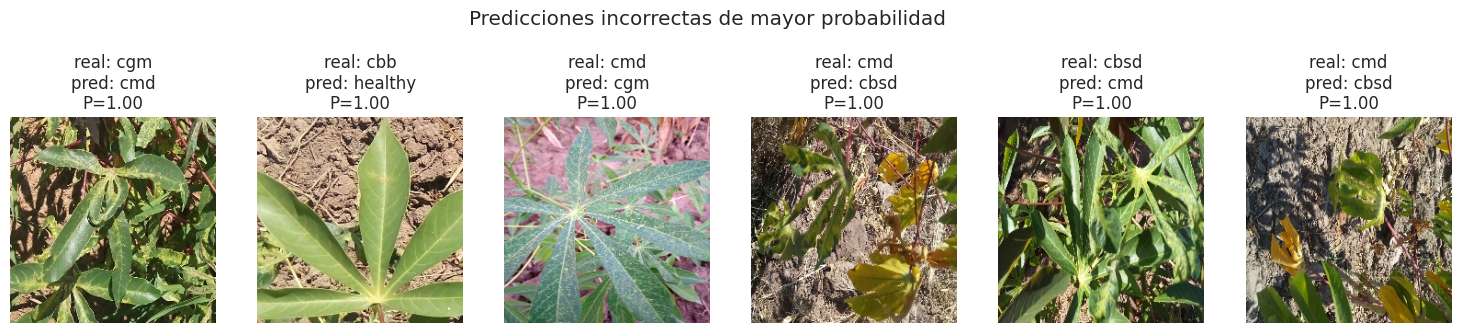

Figura guardada: resultados/figuras/predicciones_incorrectas.png


,indice,real,predicha,probabilidad_predicha,p_cbb,p_cbsd,p_cgm,p_cmd,p_healthy
0,1579,cgm,cmd,0.999977,0.000016,0.000004,0.000003,0.999977,1.330401e-08
1,411,cbb,healthy,0.998532,0.000250,0.000680,0.000531,0.000007,9.985317e-01
2,1335,cmd,cgm,0.998474,0.000786,0.000048,0.998474,0.000692,4.672300e-08
3,77,cmd,cbsd,0.997831,0.000086,0.997831,0.000003,0.002081,5.986569e-09
4,300,cbsd,cmd,0.996501,0.000010,0.000034,0.003455,0.996501,2.635016e-07
5,1864,cmd,cbsd,0.995769,0.000095,0.995769,0.000023,0.004112,7.314598e-08


Confusión más frecuente: cgm clasificada como cmd (41 imágenes).
Evaluación guardada: resultados/evaluacion_prueba.json


In [25]:
def indices_muestra(y_real, y_estimado, probabilidades, correctas, cantidad=6):
    acierto = y_real == y_estimado
    candidatos = np.flatnonzero(acierto if correctas else ~acierto)
    if len(candidatos) == 0:
        return []
    confianza = probabilidades[candidatos, y_estimado[candidatos]]
    orden = np.argsort(-confianza)
    return candidatos[orden[:cantidad]].tolist()


indices_correctos = indices_muestra(y_true, y_pred, y_prob, correctas=True)
indices_incorrectos = indices_muestra(y_true, y_pred, y_prob, correctas=False)
buscados = {int(indice): None for indice in indices_correctos + indices_incorrectos}

pipeline_visual = crear_pipeline_visual(ds_test, limite=cardinalidad_test)
for indice, (imagen, _etiqueta) in enumerate(pipeline_visual):
    if indice in buscados:
        buscados[indice] = imagen.numpy()
    if buscados and all(valor is not None for valor in buscados.values()):
        break


def mostrar_predicciones(indices, titulo, archivo):
    if not indices:
        print(titulo + ": no hay casos de este tipo.")
        return
    columnas = len(indices)
    figura, ejes = plt.subplots(1, columnas, figsize=(3.1 * columnas, 3.6))
    if columnas == 1:
        ejes = [ejes]
    filas = []
    for eje, indice in zip(ejes, indices):
        real = nombres_clases[int(y_true[indice])]
        predicha = nombres_clases[int(y_pred[indice])]
        probabilidad = float(y_prob[indice, y_pred[indice]])
        if buscados[indice] is None:
            raise RuntimeError("No se recuperó la imagen de prueba asociada a la predicción " + str(indice))
        eje.imshow(buscados[indice])
        eje.axis("off")
        eje.set_title(f"real: {real}\npred: {predicha}\nP={probabilidad:.2f}")
        fila = {
            "indice": int(indice),
            "real": real,
            "predicha": predicha,
            "probabilidad_predicha": probabilidad,
        }
        for clase_indice, codigo in enumerate(nombres_clases):
            fila["p_" + codigo] = float(y_prob[indice, clase_indice])
        filas.append(fila)
    figura.suptitle(titulo, y=1.08)
    guardar_figura(figura, archivo)
    display(pd.DataFrame(filas))


mostrar_predicciones(indices_correctos, "Predicciones correctas de mayor probabilidad", "predicciones_correctas.png")
mostrar_predicciones(indices_incorrectos, "Predicciones incorrectas de mayor probabilidad", "predicciones_incorrectas.png")

matriz_sin_diagonal = matriz.copy()
np.fill_diagonal(matriz_sin_diagonal, 0)
if matriz_sin_diagonal.sum() == 0:
    confusion_principal = None
    print("No hay confusiones fuera de la diagonal.")
else:
    origen, destino = np.unravel_index(np.argmax(matriz_sin_diagonal), matriz_sin_diagonal.shape)
    confusion_principal = {
        "real": nombres_clases[int(origen)],
        "predicha": nombres_clases[int(destino)],
        "imagenes": int(matriz_sin_diagonal[origen, destino]),
    }
    print(
        "Confusión más frecuente:",
        confusion_principal["real"],
        "clasificada como",
        confusion_principal["predicha"],
        f"({confusion_principal['imagenes']} imágenes).",
    )

indice_minoritaria = int(np.argmin(conteo_train))
evaluacion = {
    "experimento_id": ficha_mejor["experimento_id"],
    "arquitectura": ficha_mejor["arquitectura"],
    "split": "test",
    "imagenes": int(len(y_true)),
    "metricas": metricas_prueba,
    "reporte": reporte,
    "matriz_confusion": matriz.tolist(),
    "clases": nombres_clases,
    "y_true": y_true.tolist(),
    "y_pred": y_pred.tolist(),
    "probabilidades": y_prob.tolist(),
    "confusion_principal": confusion_principal,
    "clase_minoritaria_entrenamiento": {
        "clase": nombres_clases[indice_minoritaria],
        "entrenamiento": int(conteo_train[indice_minoritaria]),
        "soporte_prueba": int(reporte[nombres_clases[indice_minoritaria]]["support"]),
        "f1_prueba": float(reporte[nombres_clases[indice_minoritaria]]["f1-score"]),
        "precision_prueba": float(reporte[nombres_clases[indice_minoritaria]]["precision"]),
        "recall_prueba": float(reporte[nombres_clases[indice_minoritaria]]["recall"]),
    },
}
guardar_json(RUTA_EVALUACION, evaluacion)
print("Evaluación guardada:", RUTA_EVALUACION)
del modelo_final
liberar_memoria()

## 11. Conclusiones

El texto se redacta a partir de `resumen_experimentos.csv`, `historiales.json`, `mejor_modelo.json` y `evaluacion_prueba.json`. Si alguno de esos resultados no existe, la celda se detiene y no completa las cifras. La diferencia entre entrenamiento, validación y prueba se informa como diferencia observada, sin un umbral fijo que declare por sí solo un problema de generalización.

In [26]:
def redactar_conclusiones(historiales, ficha, evaluacion, tabla):
    registro = historiales[ficha["experimento_id"]]
    lineas = []
    lineas.append("Conclusiones de la clasificación de hojas de yuca en el conjunto cassava")
    lineas.append("")
    lineas.append(
        "El modelo seleccionado es {id}, de arquitectura {arq}, tamaño de lote {lote}, dropout {dropout:.1f}, "
        "tasa de cabeza {lr_cabeza:.0e} y tasa de ajuste fino {lr_ft:.0e}. "
        "Se conservó la fase {fase}, en su época {epoca}. "
        "En validación obtuvo macro-F1 {f1:.4f}, accuracy {acc:.4f} y pérdida {loss:.4f}. "
        "El criterio fue el mayor macro-F1 de validación, con accuracy de validación como desempate. "
        "El conjunto de prueba no intervino en esa elección.".format(
            id=ficha["experimento_id"],
            arq=ficha["arquitectura"],
            lote=int(ficha["batch_size"]),
            dropout=float(ficha["dropout"]),
            lr_cabeza=float(ficha["lr_cabeza"]),
            lr_ft=float(ficha["lr_finetuning"]),
            fase=ficha["fase_conservada"],
            epoca=int(ficha["mejor_epoca"]),
            f1=float(ficha["val_macro_f1"]),
            acc=float(ficha["val_accuracy"]),
            loss=float(ficha["val_loss"]),
        )
    )
    medias = tabla.groupby("arquitectura")["val_macro_f1"].mean()
    mejores = tabla.groupby("arquitectura")["val_macro_f1"].max()
    frases_medias = ", ".join(f"{nombre} {valor:.4f}" for nombre, valor in medias.items())
    frases_mejores = ", ".join(f"{nombre} {valor:.4f}" for nombre, valor in mejores.items())
    lineas.append(
        "En las ocho configuraciones, el macro-F1 medio de validación fue "
        + frases_medias
        + ". El mejor valor dentro de cada arquitectura fue "
        + frases_mejores
        + ". La comparación promedia lote y dropout, y cada configuración se entrenó una sola vez."
    )
    medias_dropout = tabla.groupby("dropout")["val_macro_f1"].mean()
    medias_lote = tabla.groupby("batch_size")["val_macro_f1"].mean()
    lineas.append(
        "El macro-F1 medio de validación por dropout fue "
        + ", ".join(f"{float(nombre):.1f}: {valor:.4f}" for nombre, valor in medias_dropout.items())
        + ". Por tamaño de lote fue "
        + ", ".join(f"{int(nombre)}: {valor:.4f}" for nombre, valor in medias_lote.items())
        + ". Esas medias no separan el hiperparámetro del resto de la malla, así que no se presentan como un efecto causal aislado."
    )
    delta = float(registro["val_macro_f1_finetuning"] - registro["val_macro_f1_cabeza"])
    mejoras = int((tabla["val_macro_f1_finetuning"] > tabla["val_macro_f1_cabeza"]).sum())
    lineas.append(
        "En el experimento seleccionado, el mejor macro-F1 de validación de la cabeza fue "
        f"{float(registro['val_macro_f1_cabeza']):.4f} y el del ajuste fino fue "
        f"{float(registro['val_macro_f1_finetuning']):.4f} (diferencia del ajuste fino menos la cabeza: {delta:.4f}). "
        f"En {mejoras} de 8 configuraciones el ajuste fino aumentó ese macro-F1 respecto de la cabeza."
    )
    lineas.append(
        "En la época conservada, el macro-F1 de entrenamiento fue "
        f"{float(registro['train_macro_f1_mejor_epoca']):.4f} y el de validación fue "
        f"{float(registro['val_macro_f1']):.4f}. "
        "La accuracy de entrenamiento fue "
        f"{float(registro['train_accuracy_mejor_epoca']):.4f} y la de validación fue "
        f"{float(registro['val_accuracy']):.4f}."
    )
    prueba = evaluacion["metricas"]
    lineas.append(
        "En el split test, el modelo obtuvo accuracy {acc:.4f}, precisión macro {precision:.4f}, "
        "recall macro {recall:.4f} y F1 macro {f1:.4f}, sobre {n} imágenes. "
        "Frente a la validación, la diferencia de macro-F1 (prueba − validación) fue {df1:.4f} "
        "y la de accuracy fue {dacc:.4f}.".format(
            acc=prueba["accuracy"],
            precision=prueba["precision_macro"],
            recall=prueba["recall_macro"],
            f1=prueba["f1_macro"],
            n=int(evaluacion["imagenes"]),
            df1=prueba["f1_macro"] - float(ficha["val_macro_f1"]),
            dacc=prueba["accuracy"] - float(ficha["val_accuracy"]),
        )
    )
    lineas.append("Desempeño por clase en prueba:")
    for codigo in evaluacion["clases"]:
        clase = evaluacion["reporte"][codigo]
        lineas.append(
            f"- {codigo} ({DESCRIPCIONES.get(codigo, codigo)}): "
            f"precisión {clase['precision']:.4f}, recall {clase['recall']:.4f}, "
            f"F1 {clase['f1-score']:.4f}, soporte {int(clase['support'])}."
        )
    minoritaria = evaluacion["clase_minoritaria_entrenamiento"]
    lineas.append(
        "La clase con menos ejemplos de entrenamiento fue {clase} ({n} imágenes). "
        "En prueba tuvo soporte {soporte}, precisión {precision:.4f}, recall {recall:.4f} y F1 {f1:.4f}.".format(
            clase=minoritaria["clase"],
            n=minoritaria["entrenamiento"],
            soporte=minoritaria["soporte_prueba"],
            precision=minoritaria["precision_prueba"],
            recall=minoritaria["recall_prueba"],
            f1=minoritaria["f1_prueba"],
        )
    )
    confusion = evaluacion["confusion_principal"]
    if confusion is None:
        lineas.append("La matriz de confusión de prueba no tuvo errores fuera de la diagonal.")
    else:
        lineas.append(
            "La confusión más frecuente en prueba fue {real} predicha como {predicha}, con {n} imágenes.".format(
                real=confusion["real"],
                predicha=confusion["predicha"],
                n=confusion["imagenes"],
            )
        )
    lineas.append(
        "El conjunto tiene un desbalance marcado, un tamaño moderado y fotografías de campo con fondo y encuadre variables. "
        "Las etiquetas corresponden a la condición principal anotada; una hoja puede mostrar más de un daño aunque el conjunto asigne una sola clase. "
        "Las imágenes proceden del reto iCassava 2019 y no cubren, por sí solas, otras regiones, cámaras ni campañas. "
        "CGM representa daño asociado con un ácaro, mientras que CBB, CBSD y CMD son enfermedades; el modelo solo distingue las categorías visuales del conjunto. "
        "No debe usarse como diagnóstico definitivo ni como única base para una decisión de manejo del cultivo."
    )
    lineas.append(
        "Extensiones posibles, no comprobadas en esta ejecución, son repetir cada celda de la malla con distintas semillas, "
        "probar otra familia convolucional, revisar la calibración de las probabilidades y evaluar fotografías recogidas fuera de este conjunto. "
        "También puede estudiarse un segundo anotador o la severidad del daño, información que esta versión de TensorFlow Datasets no incluye como etiqueta."
    )
    lineas.append(
        "Cifras tomadas de los archivos de esta ejecución: resumen_experimentos.csv, historiales.json, mejor_modelo.json y evaluacion_prueba.json."
    )
    return "\n".join(lineas)


historiales = cargar_json(RUTA_HISTORIALES, {})
ficha = cargar_json(RUTA_MEJOR, None)
evaluacion = cargar_json(RUTA_EVALUACION, None)
if not RUTA_RESUMEN.exists() or not isinstance(ficha, dict) or not isinstance(evaluacion, dict):
    raise RuntimeError("Aún no están los resultados de la malla completa y de la prueba. No se redactan cifras.")
tabla = pd.read_csv(RUTA_RESUMEN)
if len(tabla) != 8 or not (tabla["estado"] == "completo").all():
    raise RuntimeError("Las conclusiones requieren los ocho experimentos en estado completo.")
if evaluacion.get("experimento_id") != ficha.get("experimento_id"):
    raise RuntimeError("La evaluación de prueba no corresponde al modelo seleccionado.")

texto = redactar_conclusiones(historiales, ficha, evaluacion, tabla)
RUTA_CONCLUSIONES.write_text(texto, encoding="utf-8")
print(texto)
print("\nArchivo guardado:", RUTA_CONCLUSIONES)

Conclusiones de la clasificación de hojas de yuca en el conjunto cassava

El modelo seleccionado es completo_ResNet50_bs16_do0p3_c6_f8_p3_hlr1e-03_flr1e-05, de arquitectura ResNet50, tamaño de lote 16, dropout 0.3, tasa de cabeza 1e-03 y tasa de ajuste fino 1e-05. Se conservó la fase finetuning, en su época 4. En validación obtuvo macro-F1 0.7441, accuracy 0.8121 y pérdida 0.6346. El criterio fue el mayor macro-F1 de validación, con accuracy de validación como desempate. El conjunto de prueba no intervino en esa elección.
En las ocho configuraciones, el macro-F1 medio de validación fue MobileNetV2 0.6842, ResNet50 0.7388. El mejor valor dentro de cada arquitectura fue MobileNetV2 0.7006, ResNet50 0.7441. La comparación promedia lote y dropout, y cada configuración se entrenó una sola vez.
El macro-F1 medio de validación por dropout fue 0.3: 0.7147, 0.5: 0.7082. Por tamaño de lote fue 16: 0.7184, 32: 0.7046. Esas medias no separan el hiperparámetro del resto de la malla, así que no se p

## 12. Referencias

- TensorFlow Datasets. *cassava*. https://www.tensorflow.org/datasets/catalog/cassava
- Mwebaze, E., Gebru, T., Frome, A., Nsumba, S. y Tusubira, J. (2019). *iCassava 2019 Fine-Grained Visual Categorization Challenge*. arXiv:1908.02900. https://arxiv.org/abs/1908.02900
- Sandler, M., Howard, A., Zhu, M., Zhmoginov, A. y Chen, L.-C. (2018). *MobileNetV2: Inverted Residuals and Linear Bottlenecks*. IEEE/CVF Conference on Computer Vision and Pattern Recognition. https://arxiv.org/abs/1801.04381
- He, K., Zhang, X., Ren, S. y Sun, J. (2016). *Deep Residual Learning for Image Recognition*. IEEE Conference on Computer Vision and Pattern Recognition. https://arxiv.org/abs/1512.03385
- Russakovsky, O., Deng, J., Su, H., Krause, J., Satheesh, S., Ma, S., Huang, Z., Karpathy, A., Khosla, A., Bernstein, M., Berg, A. C. y Fei-Fei, L. (2015). *ImageNet Large Scale Visual Recognition Challenge*. International Journal of Computer Vision, 115(3), 211-252. https://arxiv.org/abs/1409.0575
- Keras. *Applications*. https://keras.io/api/applications/
- Keras. *Transfer learning and fine-tuning*. https://keras.io/guides/transfer_learning/
- TensorFlow. *tf.data: Build TensorFlow input pipelines*. https://www.tensorflow.org/guide/data
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M. y Duchesnay, É. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825-2830. https://jmlr.org/papers/v12/pedregosa11a.html

## Resultados y descarga

Al terminar la malla completa, la evaluación y las conclusiones, la carpeta `resultados/` contiene:

- `resumen_experimentos.csv`
- `historiales.json`
- `mejor_modelo.json`
- `evaluacion_prueba.json`
- `conclusiones.txt`
- `mejor_modelo.keras`
- `checkpoints/`
- `figuras/`

La celda siguiente comprime esa carpeta. En Google Colab también inicia la descarga del ZIP. El archivo puede ser grande porque incluye los checkpoints.

Para conservar el notebook con tablas, figuras y texto ya ejecutados: **Archivo → Descargar → Descargar .ipynb**. Conviene descargar tanto el notebook como el ZIP antes de cerrar la sesión. Si Colab reinicia la máquina virtual, el disco local se borra; con `USAR_GOOGLE_DRIVE = True` los mismos archivos quedan en Drive.

In [27]:
print("Contenido de", RESULTADOS.resolve())
for ruta in sorted(RESULTADOS.rglob("*")):
    if ruta.is_file():
        print(f"  {ruta.relative_to(RESULTADOS)}  ({ruta.stat().st_size} bytes)")

archivo_zip = Path("resultados_cassava.zip")
if archivo_zip.exists():
    archivo_zip.unlink()
if RESULTADOS.is_absolute():
    shutil.make_archive("resultados_cassava", "zip", root_dir=str(RESULTADOS.parent), base_dir=RESULTADOS.name)
else:
    shutil.make_archive("resultados_cassava", "zip", root_dir=".", base_dir=str(RESULTADOS))
print("ZIP creado:", archivo_zip.resolve(), "(", archivo_zip.stat().st_size, "bytes)")

if EN_COLAB:
    from google.colab import files
    files.download(str(archivo_zip))
else:
    print("La descarga automática del navegador está disponible al ejecutar esta celda en Google Colab.")

Contenido de /content/resultados
  checkpoints/completo_MobileNetV2_bs16_do0p3_c6_f8_p3_hlr1e-03_flr1e-05/mejor.keras  (33940972 bytes)
  checkpoints/completo_MobileNetV2_bs16_do0p5_c6_f8_p3_hlr1e-03_flr1e-05/mejor.keras  (33940972 bytes)
  checkpoints/completo_MobileNetV2_bs32_do0p3_c6_f8_p3_hlr1e-03_flr1e-05/mejor.keras  (33940972 bytes)
  checkpoints/completo_MobileNetV2_bs32_do0p5_c6_f8_p3_hlr1e-03_flr1e-05/mejor.keras  (33940972 bytes)
  checkpoints/completo_ResNet50_bs16_do0p3_c6_f8_p3_hlr1e-03_flr1e-05/mejor.keras  (334506151 bytes)
  checkpoints/completo_ResNet50_bs16_do0p5_c6_f8_p3_hlr1e-03_flr1e-05/mejor.keras  (334506151 bytes)
  checkpoints/completo_ResNet50_bs32_do0p3_c6_f8_p3_hlr1e-03_flr1e-05/mejor.keras  (334506151 bytes)
  checkpoints/completo_ResNet50_bs32_do0p5_c6_f8_p3_hlr1e-03_flr1e-05/mejor.keras  (334506151 bytes)
  conclusiones.txt  (3691 bytes)
  evaluacion_prueba.json  (315050 bytes)
  figuras/cambio_finetuning.png  (83399 bytes)
  figuras/comparacion_configur

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>